# Noise-Robust Quantum Machine Learning for Building Energy Performance

## Original-scope FULL experiment with five independent seeds

This paper-oriented notebook preserves the original study design—classical regressors, a four-qubit QNN, six input-noise families, matched-noise training, and warm-start SPSA—while strengthening the statistical protocol.

All primary experiments use five predeclared seeds. Every seed controls its own split, subset, model initialization, and corruption streams. Noise magnitudes and clipping bounds are estimated from that seed's training data only. Raw seed-level results are retained; reported uncertainty is the sample standard deviation and a two-sided 95% Student-t confidence interval across seeds.

The notebook does **not** claim quantum advantage. It is intended as a reproducible, respectable first-submission experiment on a small simulated-building benchmark.


## 1. Research questions and estimands

1. How much does clean-test performance degrade under six controlled input corruptions?
2. Do degradation patterns differ by target and model?
3. Does matched noisy training improve robustness?
4. On identical small subsets, how does a shallow QNN compare with classical baselines?
5. Can warm-start SPSA recover performance under selected corruptions?

The unit of replication is the **seed-level experimental run**, not a row, prediction, severity point, or optimizer evaluation. Heating and Cooling Load are analyzed separately. Quantum simulation is limited to Heating Load because of its substantially higher computational cost.


## 2. Imports, FULL-mode configuration, and statistical helpers


In [1]:
from pathlib import Path
import importlib.util, json, platform, random, sys, time, warnings

FAST_MODE = False
FULL_EXPERIMENT_MODE = True
RUN_QUANTUM = True
BASE_SEED = 42
RANDOM_SEED = BASE_SEED
EXPERIMENT_SEEDS = [11, 23, 42, 71, 101]
QUANTUM_SEEDS = EXPERIMENT_SEEDS.copy()

DATASET_PATH = Path("ENB2012_data.xlsx")
RESULTS_DIR = Path("results_paper_full_5seeds")

assert FULL_EXPERIMENT_MODE and not FAST_MODE, "This artifact is intentionally fixed to FULL mode."
assert len(EXPERIMENT_SEEDS) == 5 and len(set(EXPERIMENT_SEEDS)) == 5
SEVERITIES = [0.0, 0.1, 0.2, 0.3, 0.4]
QUANTUM_TRAIN_SIZE = 96
QUANTUM_TEST_SIZE = 64
REQUESTED_QNN_BUDGET = 80
CONVERGENCE_BUDGETS = [40, 80, 120]
ANSATZ_REPS_CANDIDATES = [1, 2]
ABLATION_SEEDS = EXPERIMENT_SEEDS[:3]
VALIDATION_FRACTION = 0.20
PRACTICAL_RMSE_TOLERANCE = 0.10
SPSA_ITERATIONS = 30
MATCHED_CONDITIONS = [("gaussian", 0.3), ("missingness", 0.3), ("outlier", 0.3)]
SPSA_CONDITIONS = [("gaussian", 0.3), ("missingness", 0.3)]

def seed_roles(base_seed):
    return {
        "split": base_seed,
        "subset": base_seed + 100,
        "initialization": base_seed + 200,
        "train_corruption": base_seed + 300,
        "test_corruption": base_seed + 400,
        "spsa": base_seed + 500,
    }

random.seed(BASE_SEED)
for folder in [RESULTS_DIR, RESULTS_DIR/"tables", RESULTS_DIR/"plots"]:
    folder.mkdir(parents=True, exist_ok=True)
print("Mode: FULL | independent seeds:", EXPERIMENT_SEEDS)


Mode: FULL | independent seeds: [11, 23, 42, 71, 101]


In [2]:
required = ["numpy", "pandas", "scipy", "sklearn", "matplotlib", "seaborn", "openpyxl"]
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    raise ImportError(
        "Missing packages: " + ", ".join(missing) +
        ". Install them in this notebook environment, restart the kernel, and run all cells again."
    )

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.integrate import trapezoid
from scipy.stats import t as student_t
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.svm import SVR

np.random.seed(BASE_SEED)
sns.set_theme(style="whitegrid", context="notebook")

def summarize_across_seeds(frame, group_columns, metrics):
    # One observation per seed and group is required.
    if frame.empty:
        return pd.DataFrame()
    duplicate_keys = ["seed", *group_columns]
    if frame.duplicated(duplicate_keys).any():
        raise ValueError(f"Expected one row per {duplicate_keys}; aggregate within seed before calling.")
    rows = []
    for keys, group in frame.groupby(group_columns, dropna=False, sort=False):
        keys = keys if isinstance(keys, tuple) else (keys,)
        row = dict(zip(group_columns, keys))
        n = group["seed"].nunique()
        row["n_seeds"] = n
        for metric in metrics:
            values = group[metric].dropna().astype(float)
            count = len(values)
            mean = values.mean() if count else np.nan
            sd = values.std(ddof=1) if count > 1 else np.nan
            se = sd / np.sqrt(count) if count > 1 else np.nan
            critical = student_t.ppf(0.975, count - 1) if count > 1 else np.nan
            row[f"{metric}_mean"] = mean
            row[f"{metric}_sd"] = sd
            row[f"{metric}_se"] = se
            row[f"{metric}_ci95_low"] = mean - critical * se if count > 1 else np.nan
            row[f"{metric}_ci95_high"] = mean + critical * se if count > 1 else np.nan
        rows.append(row)
    return pd.DataFrame(rows)

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)


Python 3.13.14 | numpy 2.2.3 | pandas 2.2.3


## 3. Dataset loading and exploration

The workbook is inspected rather than assuming its worksheet name. Fully empty trailing rows and columns are removed; the ten populated columns are verified before readable names are assigned.


Workbook: C:\Users\LENOVO\Downloads\ENB2012_data.xlsx
Worksheets: [{'worksheet': 'Φύλλο1', 'rows': 768, 'columns': 10}, {'worksheet': 'Φύλλο2', 'rows': 0, 'columns': 0}, {'worksheet': 'Φύλλο3', 'rows': 0, 'columns': 0}]
Selected sheet: Φύλλο1 | cleaned shape: (768, 10) | duplicates: 0


,column,dtype,missing,unique,minimum,maximum
0,Relative_Compactness,float64,0,12,0.62,0.98
1,Surface_Area,float64,0,12,514.50,808.50
2,Wall_Area,float64,0,7,245.00,416.50
3,Roof_Area,float64,0,4,110.25,220.50
4,Overall_Height,float64,0,2,3.50,7.00
5,Orientation,int64,0,4,2.00,5.00
6,Glazing_Area,float64,0,4,0.00,0.40
7,Glazing_Area_Distribution,int64,0,6,0.00,5.00
8,Heating_Load,float64,0,587,6.01,43.10
9,Cooling_Load,float64,0,636,10.90,48.03


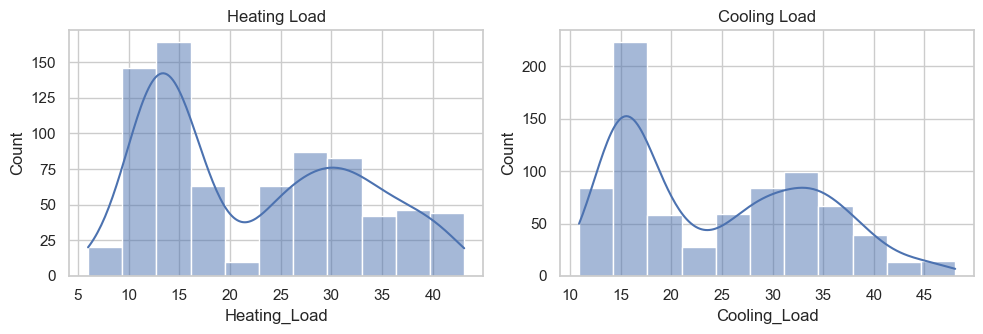

In [3]:
COLUMN_MAP = {
    "X1":"Relative_Compactness", "X2":"Surface_Area", "X3":"Wall_Area", "X4":"Roof_Area",
    "X5":"Overall_Height", "X6":"Orientation", "X7":"Glazing_Area", "X8":"Glazing_Area_Distribution",
    "Y1":"Heating_Load", "Y2":"Cooling_Load"
}
FEATURES = list(COLUMN_MAP.values())[:8]
TARGETS = ["Heating_Load", "Cooling_Load"]
CONTINUOUS = ["Relative_Compactness", "Surface_Area", "Wall_Area", "Roof_Area", "Overall_Height", "Glazing_Area"]
DISCRETE = ["Orientation", "Glazing_Area_Distribution"]

def find_dataset(filename):
    candidates = [Path(filename), Path.cwd()/Path(filename).name, Path.home()/"Downloads"/Path(filename).name]
    found = next((p.resolve() for p in candidates if p.exists()), None)
    if found is None:
        raise FileNotFoundError(f"Place {Path(filename).name} beside this notebook or update DATASET_PATH.")
    return found

dataset_file = find_dataset(DATASET_PATH)
excel = pd.ExcelFile(dataset_file, engine="openpyxl")
sheet_summary=[]; raw=None; selected_sheet=None
for sheet in excel.sheet_names:
    candidate = pd.read_excel(dataset_file, sheet_name=sheet, engine="openpyxl")
    candidate = candidate.dropna(axis=0, how="all").dropna(axis=1, how="all")
    sheet_summary.append({"worksheet":sheet, "rows":len(candidate), "columns":candidate.shape[1]})
    if raw is None and len(candidate):
        raw, selected_sheet = candidate, sheet

raw.columns = [str(c).strip() for c in raw.columns]
assert set(COLUMN_MAP).issubset(raw.columns), f"Unexpected columns: {raw.columns.tolist()}"
data = raw[list(COLUMN_MAP)].rename(columns=COLUMN_MAP).apply(pd.to_numeric, errors="coerce")

audit = pd.DataFrame({
    "column":data.columns, "dtype":data.dtypes.astype(str).values,
    "missing":data.isna().sum().values, "unique":data.nunique().values,
    "minimum":data.min().values, "maximum":data.max().values
})
print("Workbook:", dataset_file)
print("Worksheets:", sheet_summary)
print("Selected sheet:", selected_sheet, "| cleaned shape:", data.shape,
      "| duplicates:", int(data.duplicated().sum()))
display(audit)
audit.to_csv(RESULTS_DIR/"tables"/"dataset_audit.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, target in zip(axes, TARGETS):
    sns.histplot(data[target], kde=True, ax=ax)
    ax.set_title(target.replace("_", " "))
fig.tight_layout(); plt.show()


## 4. Leakage-safe repeated splits and preprocessing

Every seed generates a separate 80/20 split. Imputation, scaling, PCA, target scaling, and noise-reference statistics are fitted on that seed's training observations only. The sample standard deviation (`ddof=1`) defines additive noise scales; zero-variance scales are safely replaced by one.


In [4]:
X = data[FEATURES]
y = data[TARGETS]

def compute_noise_stats(training_frame):
    return {
        "std": training_frame[CONTINUOUS].std(ddof=1).replace(0, 1),
        "min": training_frame[CONTINUOUS].min(),
        "max": training_frame[CONTINUOUS].max(),
    }

def make_split(seed):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=seed
    )
    return {
        "seed": seed, "X_train": X_train.copy(), "X_test": X_test.copy(),
        "y_train": y_train.copy(), "y_test": y_test.copy(),
        "noise_stats": compute_noise_stats(X_train),
    }

def make_classical_models(seed=RANDOM_SEED):
    scaled = lambda model: Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model)
    ])
    return {
        "Ridge": scaled(Ridge(alpha=1.0)),
        "Random Forest": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestRegressor(
                n_estimators=200, min_samples_leaf=2, random_state=seed, n_jobs=-1
            ))
        ]),
        "RBF SVR": scaled(SVR(C=20.0, epsilon=0.1, gamma="scale"))
    }

def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred)**0.5,
        "R2": r2_score(y_true, y_pred)
    }

classical_runs = {seed: make_split(seed) for seed in EXPERIMENT_SEEDS}


## 5. Repeated classical baselines

Each model is refitted on every seed's full training split. Seed-level results are the raw inferential units. The summary table reports mean, sample SD, standard error, and a two-sided 95% t-interval across the five runs.


In [5]:
baseline_rows = []
for seed, run in classical_runs.items():
    run["models"] = {}
    for target in TARGETS:
        for model_name, model in make_classical_models(seed).items():
            start = time.perf_counter()
            model.fit(run["X_train"], run["y_train"][target])
            training_time = time.perf_counter() - start
            start = time.perf_counter()
            prediction = model.predict(run["X_test"])
            evaluation_time = time.perf_counter() - start
            run["models"][(target, model_name)] = model
            baseline_rows.append({
                "seed": seed, "target": target, "model": model_name,
                **regression_metrics(run["y_test"][target], prediction),
                "training_runtime_seconds": training_time,
                "evaluation_runtime_seconds": evaluation_time,
            })

classical_baselines = pd.DataFrame(baseline_rows).sort_values(["target", "model", "seed"])
classical_baseline_summary = summarize_across_seeds(
    classical_baselines, ["target", "model"],
    ["MAE", "RMSE", "R2", "training_runtime_seconds", "evaluation_runtime_seconds"]
)
display(classical_baseline_summary)
classical_baselines.to_csv(RESULTS_DIR/"tables"/"classical_baselines_by_seed.csv", index=False)
classical_baseline_summary.to_csv(RESULTS_DIR/"tables"/"classical_baseline_summary.csv", index=False)


,target,model,n_seeds,MAE_mean,MAE_sd,MAE_se,MAE_ci95_low,MAE_ci95_high,RMSE_mean,RMSE_sd,...,training_runtime_seconds_mean,training_runtime_seconds_sd,training_runtime_seconds_se,training_runtime_seconds_ci95_low,training_runtime_seconds_ci95_high,evaluation_runtime_seconds_mean,evaluation_runtime_seconds_sd,evaluation_runtime_seconds_se,evaluation_runtime_seconds_ci95_low,evaluation_runtime_seconds_ci95_high
0,Cooling_Load,RBF SVR,5,1.508420,0.128793,0.057598,1.348502,1.668338,2.424566,0.187030,...,0.072762,0.012174,0.005445,0.057646,0.087879,0.017770,0.002633,0.001178,0.014501,0.021040
1,Cooling_Load,Random Forest,5,1.080598,0.115395,0.051606,0.937317,1.223880,1.729968,0.147258,...,0.522787,0.029742,0.013301,0.485857,0.559717,0.097852,0.006061,0.002711,0.090326,0.105378
2,Cooling_Load,Ridge,5,2.198740,0.166144,0.074302,1.992445,2.405034,3.120870,0.243359,...,0.008588,0.001208,0.000540,0.007088,0.010089,0.002782,0.000384,0.000172,0.002304,0.003259
3,Heating_Load,RBF SVR,5,1.137664,0.153981,0.068862,0.946472,1.328857,2.098679,0.250188,...,0.086475,0.004141,0.001852,0.081334,0.091616,0.016703,0.001961,0.000877,0.014268,0.019137
4,Heating_Load,Random Forest,5,0.347607,0.056477,0.025257,0.277481,0.417733,0.514458,0.089796,...,0.502035,0.036478,0.016313,0.456742,0.547328,0.101106,0.006330,0.002831,0.093246,0.108967
5,Heating_Load,Ridge,5,2.092934,0.154595,0.069137,1.900979,2.284889,2.929292,0.180408,...,0.009491,0.001469,0.000657,0.007667,0.011316,0.002943,0.000533,0.000239,0.002281,0.003605


## 6. Six input-noise models and realized-corruption audit

- **Gaussian:** zero-mean additive error with SD = severity × training SD.
- **Multiplicative:** zero-mean relative error with SD = severity.
- **Systematic bias:** one signed shift per continuous feature and seed, magnitude = severity × training SD.
- **Missingness:** independent masking with probability = severity across all eight inputs.
- **Rounding:** quantization step = severity × training range / 3.
- **Outlier:** independent contamination with probability = severity and jump = ±3 training SD.

Continuous values are clipped to that seed's observed training domain. Severity zero is exactly unchanged. A common random stream is reused across severity levels within each seed/noise family, making severity curves paired while seeds remain independent. Realized corruption—not just nominal severity—is saved for audit.


In [6]:
NOISE_TYPES = ["gaussian", "multiplicative", "systematic_bias", "missingness", "rounding", "outlier"]

def add_noise(frame, noise_type, severity, seed, reference_stats, feature_only=None):
    noisy = frame.copy(deep=True)
    if severity == 0:
        return noisy
    rng = np.random.default_rng(seed)
    continuous = [c for c in CONTINUOUS if feature_only is None or c == feature_only]
    eligible = FEATURES if feature_only is None else [feature_only]

    if noise_type == "gaussian":
        scale = severity * reference_stats["std"][continuous].to_numpy()
        noisy.loc[:, continuous] = noisy[continuous].to_numpy() + rng.normal(
            size=(len(noisy), len(continuous))
        ) * scale
    elif noise_type == "multiplicative":
        noisy.loc[:, continuous] = noisy[continuous].to_numpy() * (
            1 + rng.normal(0, severity, size=(len(noisy), len(continuous)))
        )
    elif noise_type == "systematic_bias":
        directions = rng.choice([-1, 1], len(continuous))
        noisy.loc[:, continuous] = noisy[continuous].to_numpy() + (
            severity * reference_stats["std"][continuous].to_numpy() * directions
        )
    elif noise_type == "missingness":
        mask = rng.random((len(noisy), len(eligible))) < severity
        noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
    elif noise_type == "rounding":
        for column in continuous:
            value_range = reference_stats["max"][column] - reference_stats["min"][column]
            step = max(value_range * severity / 3, 1e-8)
            noisy[column] = np.round(noisy[column] / step) * step
    elif noise_type == "outlier":
        mask = rng.random((len(noisy), len(continuous))) < severity
        jumps = rng.choice([-1, 1], mask.shape) * 3 * reference_stats["std"][continuous].to_numpy()
        noisy.loc[:, continuous] = noisy[continuous].to_numpy() + mask * jumps
    else:
        raise ValueError(f"Unknown noise type: {noise_type}")

    for column in continuous:
        noisy[column] = noisy[column].clip(
            reference_stats["min"][column], reference_stats["max"][column]
        )
    return noisy

def corruption_summary(clean, noisy, reference_stats, feature_only=None):
    eligible = FEATURES if feature_only is None else [feature_only]
    continuous = [c for c in CONTINUOUS if c in eligible]
    changed = clean[eligible].ne(noisy[eligible]) | clean[eligible].isna().ne(noisy[eligible].isna())
    missing = noisy[eligible].isna()
    if continuous:
        standardized = (
            (noisy[continuous] - clean[continuous]).abs()
            / reference_stats["std"][continuous]
        )
        standardized_mae = float(standardized.stack().mean()) if standardized.notna().any().any() else 0.0
    else:
        standardized_mae = 0.0
    return {
        "eligible_cells": int(clean[eligible].size),
        "realized_changed_fraction": float(changed.to_numpy().mean()),
        "realized_missing_fraction": float(missing.to_numpy().mean()),
        "standardized_absolute_corruption_mean": standardized_mae,
    }

validation_rows = []
for seed, run in classical_runs.items():
    roles = seed_roles(seed)
    for noise_index, noise_type in enumerate(NOISE_TYPES):
        corruption_seed = roles["test_corruption"] + 1000 * noise_index
        for severity in SEVERITIES:
            noisy = add_noise(
                run["X_test"], noise_type, severity, corruption_seed, run["noise_stats"]
            )
            validation_rows.append({
                "seed": seed, "noise_type": noise_type, "severity": severity,
                **corruption_summary(run["X_test"], noisy, run["noise_stats"])
            })
            if severity == 0:
                assert noisy.equals(run["X_test"])

noise_validation = pd.DataFrame(validation_rows)
noise_validation_summary = summarize_across_seeds(
    noise_validation, ["noise_type", "severity"],
    ["realized_changed_fraction", "realized_missing_fraction",
     "standardized_absolute_corruption_mean"]
)
display(noise_validation_summary)
noise_validation.to_csv(RESULTS_DIR/"tables"/"noise_validation_by_seed.csv", index=False)
noise_validation_summary.to_csv(RESULTS_DIR/"tables"/"noise_validation_summary.csv", index=False)


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 4.  2.  3.  3.  2.  2.  3.  4. nan  4.  4. nan  3.  2. nan nan  4. nan
  2.  3. nan nan  3.  2.  5.  3.  3. nan  5.  2.  5.  3. nan  2.  3.  2.
  2.  2.  3.  3.  5.  4.  3.  2.  3.  3.  5.  2.  5.  2.  2.  4.  4.  3.
  2.  2.  3.  5.  5.  2.  2.  3.  4.  2.  3.  5.  2. nan  2.  3.  4.  2.
  4.  4. nan  3. nan  5. nan nan  5.  5.  5.  3.  2.  3.  4. nan  5.  3.
  5.  5.  5.  4.  2.  5.  5.  3.  5. nan  4.  3.  4.  5. nan  5.  3.  2.
  2.  2.  2. nan  5.  2.  2.  3.  4.  3.  5.  4.  3.  5.  5.  3.  4.  3.
  3. nan  3.  2.  4.  3. nan  2.  5.  2.  3.  3.  5.  2.  3.  2.  4.  5.
  2.  4.  3.  5.  2.  4.  3.  3.  3. nan]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
C:\Users\LENOVO\AppData\Local\Te

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 3.  2.  2.  5.  2. nan  3.  5. nan  4. nan  2.  5.  4.  2.  4.  4.  4.
  5.  5.  5.  2.  5.  2. nan  5.  2.  4.  4.  5.  4.  5.  3.  2.  2.  5.
  3.  4.  2.  5.  2.  4.  5. nan  5.  2.  5.  3.  5.  3.  3.  5.  3. nan
  3.  4.  5.  4.  4.  4.  2.  4.  4.  4.  2.  4.  3.  5.  5.  3.  4.  4.
 nan  4.  3.  3.  5.  4.  3.  2.  5.  2.  5.  3.  4.  4.  5.  3.  2.  5.
  2.  3.  3.  2. nan  4.  4.  5.  5.  3.  3.  5.  5.  5.  2.  3.  3.  5.
 nan  3.  3.  2.  4.  3. nan  2.  3.  3.  5.  3.  4.  5.  2.  4.  4.  4.
  4.  3.  4.  2.  5.  3.  4.  2. nan  3.  2.  2.  3.  4.  4.  3.  4.  4.
  2.  4.  3.  5.  3.  3.  4.  2. nan  2.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
C:\Users\LENOVO\AppData\Local\Te

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[nan  2.  2.  4.  3.  2.  3.  2.  2.  2.  5.  2.  5.  3. nan  2.  3.  3.
  2.  3.  2.  2.  4.  2.  3.  3. nan  5.  2. nan  2.  5.  3.  2.  5.  4.
  5.  4.  4.  4.  4.  2.  4.  5.  3.  5.  5.  3.  5.  5.  3.  2.  5.  5.
  5.  4. nan  4.  2.  2.  4.  2. nan  4.  5.  5.  4.  2.  5.  3.  4.  2.
  2.  3.  5.  4.  4.  2.  2.  4.  2.  2.  4.  2.  3.  2.  5.  3. nan  5.
  3.  4. nan nan  3.  4.  4.  4.  2.  2.  2.  4.  2. nan  4.  2.  5.  2.
  5.  4. nan  2.  3.  4.  5.  3. nan  2.  3.  5. nan  5.  5.  5.  3.  5.
  4.  5.  3.  3.  4.  5.  4.  2. nan  4.  5. nan  5.  3.  5.  4.  3.  4.
  3. nan  4.  5.  3.  5. nan  2.  2.  4.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
C:\Users\LENOVO\AppData\Local\Te

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 2.  5. nan nan  2.  5.  3.  4.  4.  3.  2.  3.  4.  3.  4. nan  5.  4.
  5.  3.  4.  2.  4.  4. nan  3.  2.  4.  4.  3.  2.  5. nan  2.  2.  2.
  4.  3.  5.  2.  2.  4.  4.  2. nan  4.  5.  3.  4.  5.  5. nan  3.  3.
  5.  5.  5.  3.  3.  4.  3.  5.  2.  2.  2.  4.  5.  4.  3.  3.  4.  2.
  5.  3.  4.  5.  2.  5.  4.  2.  2.  4.  2.  2.  2.  5.  4. nan nan  3.
  5.  2.  2.  5.  4.  2.  3.  3.  5.  2.  4.  5.  2.  5. nan  5.  2.  4.
 nan  2.  2.  2.  4.  3.  3.  3.  2.  4.  5.  3.  3.  5.  2. nan  5.  4.
  3.  3.  2.  2.  2.  3.  5.  5.  3.  4.  3.  4.  2.  5.  3.  3.  2.  4.
  3.  4.  4.  3. nan  2.  3.  4.  5. nan]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
C:\Users\LENOVO\AppData\Local\Te

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 4. nan  4.  3.  5.  3.  5.  2.  2. nan  3. nan  2.  2.  4.  5.  5.  3.
  2.  4.  4.  2.  3.  5.  5.  5.  4.  5.  4.  5.  2.  5.  4.  4. nan  4.
  2. nan  2.  4.  3.  2.  3.  4.  4.  3.  3.  4. nan  4.  4.  3.  2.  3.
  4.  3.  4.  5.  4.  5.  5. nan nan nan  3.  3.  3. nan  3.  3.  4.  3.
  4.  2.  5. nan  5.  2.  4.  5. nan  5.  3.  2.  5.  4.  4.  5.  4.  2.
  3.  3.  2.  5.  3.  4.  2.  4.  2.  5.  2.  3.  3.  2.  3.  5.  4.  4.
  3.  2.  4.  4.  2. nan  2.  2.  4.  4.  3.  2.  4.  2.  2.  2.  2.  5.
  4.  5.  3.  2.  3.  3.  5.  5.  2.  3.  4.  5.  4.  3.  2.  4.  2.  2.
  3.  2.  4.  4.  5. nan  4. nan  2.  4.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
C:\Users\LENOVO\AppData\Local\Te

,noise_type,severity,n_seeds,realized_changed_fraction_mean,realized_changed_fraction_sd,realized_changed_fraction_se,realized_changed_fraction_ci95_low,realized_changed_fraction_ci95_high,realized_missing_fraction_mean,realized_missing_fraction_sd,realized_missing_fraction_se,realized_missing_fraction_ci95_low,realized_missing_fraction_ci95_high,standardized_absolute_corruption_mean_mean,standardized_absolute_corruption_mean_sd,standardized_absolute_corruption_mean_se,standardized_absolute_corruption_mean_ci95_low,standardized_absolute_corruption_mean_ci95_high
0,gaussian,0.0,5,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,gaussian,0.1,5,0.596266,0.009614,0.004300,0.584328,0.608204,0.000000,0.000000,0.000000,0.000000,0.000000,0.064039,0.002140,0.000957,0.061382,0.066696
2,gaussian,0.2,5,0.596266,0.009614,0.004300,0.584328,0.608204,0.000000,0.000000,0.000000,0.000000,0.000000,0.127624,0.004214,0.001884,0.122392,0.132856
3,gaussian,0.3,5,0.596266,0.009614,0.004300,0.584328,0.608204,0.000000,0.000000,0.000000,0.000000,0.000000,0.190216,0.006453,0.002886,0.182204,0.198228
4,gaussian,0.4,5,0.596266,0.009614,0.004300,0.584328,0.608204,0.000000,0.000000,0.000000,0.000000,0.000000,0.251217,0.008859,0.003962,0.240216,0.262217
5,multiplicative,0.0,5,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
6,multiplicative,0.1,5,0.591558,0.014547,0.006506,0.573496,0.609621,0.000000,0.000000,0.000000,0.000000,0.000000,0.325649,0.009114,0.004076,0.314333,0.336965
7,multiplicative,0.2,5,0.591558,0.014547,0.006506,0.573496,0.609621,0.000000,0.000000,0.000000,0.000000,0.000000,0.581133,0.019637,0.008782,0.556750,0.605515
8,multiplicative,0.3,5,0.591558,0.014547,0.006506,0.573496,0.609621,0.000000,0.000000,0.000000,0.000000,0.000000,0.758064,0.025902,0.011584,0.725903,0.790225
9,multiplicative,0.4,5,0.591558,0.014547,0.006506,0.573496,0.609621,0.000000,0.000000,0.000000,0.000000,0.000000,0.880287,0.030027,0.013428,0.843004,0.917570


## 7. Repeated classical robustness experiment

Within each seed, a clean-trained model is evaluated on paired corruption curves. Clean RMSE is seed-specific. Degradation is computed within seed before cross-seed aggregation, preserving the repeated-run design.


In [7]:
robustness_rows = []
for seed, run in classical_runs.items():
    roles = seed_roles(seed)
    baseline_lookup = classical_baselines[classical_baselines.seed == seed].set_index(["target", "model"])
    for target in TARGETS:
        for model_name in make_classical_models(seed):
            model = run["models"][(target, model_name)]
            clean_rmse = float(baseline_lookup.loc[(target, model_name), "RMSE"])
            for noise_index, noise_type in enumerate(NOISE_TYPES):
                corruption_seed = roles["test_corruption"] + 1000 * noise_index
                for severity in SEVERITIES:
                    noisy_test = add_noise(
                        run["X_test"], noise_type, severity,
                        corruption_seed, run["noise_stats"]
                    )
                    start = time.perf_counter()
                    prediction = model.predict(noisy_test)
                    evaluation_time = time.perf_counter() - start
                    score = regression_metrics(run["y_test"][target], prediction)
                    robustness_rows.append({
                        "seed": seed, "target": target, "model": model_name,
                        "noise_type": noise_type, "severity": severity, **score,
                        "clean_RMSE": clean_rmse,
                        "RMSE_increase": score["RMSE"] - clean_rmse,
                        "relative_RMSE_increase": score["RMSE"] / clean_rmse - 1,
                        "evaluation_runtime_seconds": evaluation_time,
                    })

classical_robustness = pd.DataFrame(robustness_rows)
classical_robustness_summary = summarize_across_seeds(
    classical_robustness, ["target", "model", "noise_type", "severity"],
    ["MAE", "RMSE", "R2", "RMSE_increase", "relative_RMSE_increase"]
)
display(classical_robustness_summary.head())
classical_robustness.to_csv(RESULTS_DIR/"tables"/"classical_robustness_by_seed.csv", index=False)
classical_robustness_summary.to_csv(RESULTS_DIR/"tables"/"classical_robustness_summary.csv", index=False)


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 4.  2.  3.  3.  2.  2.  3.  4. nan  4.  4. nan  3.  2. nan nan  4. nan
  2.  3. nan nan  3.  2.  5.  3.  3. nan  5.  2.  5.  3. nan  2.  3.  2.
  2.  2.  3.  3.  5.  4.  3.  2.  3.  3.  5.  2.  5.  2.  2.  4.  4.  3.
  2.  2.  3.  5.  5.  2.  2.  3.  4.  2.  3.  5.  2. nan  2.  3.  4.  2.
  4.  4. nan  3. nan  5. nan nan  5.  5.  5.  3.  2.  3.  4. nan  5.  3.
  5.  5.  5.  4.  2.  5.  5.  3.  5. nan  4.  3.  4.  5. nan  5.  3.  2.
  2.  2.  2. nan  5.  2.  2.  3.  4.  3.  5.  4.  3.  5.  5.  3.  4.  3.
  3. nan  3.  2.  4.  3. nan  2.  5.  2.  3.  3.  5.  2.  3.  2.  4.  5.
  2.  4.  3.  5.  2.  4.  3.  3.  3. nan]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
C:\Users\LENOVO\AppData\Local\Te

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 4.  2.  3.  3.  2.  2.  3.  4. nan  4.  4. nan  3.  2. nan nan  4. nan
  2.  3. nan nan  3.  2.  5.  3.  3. nan  5.  2.  5.  3. nan  2.  3.  2.
  2.  2.  3.  3.  5.  4.  3.  2.  3.  3.  5.  2.  5.  2.  2.  4.  4.  3.
  2.  2.  3.  5.  5.  2.  2.  3.  4.  2.  3.  5.  2. nan  2.  3.  4.  2.
  4.  4. nan  3. nan  5. nan nan  5.  5.  5.  3.  2.  3.  4. nan  5.  3.
  5.  5.  5.  4.  2.  5.  5.  3.  5. nan  4.  3.  4.  5. nan  5.  3.  2.
  2.  2.  2. nan  5.  2.  2.  3.  4.  3.  5.  4.  3.  5.  5.  3.  4.  3.
  3. nan  3.  2.  4.  3. nan  2.  5.  2.  3.  3.  5.  2.  3.  2.  4.  5.
  2.  4.  3.  5.  2.  4.  3.  3.  3. nan]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
C:\Users\LENOVO\AppData\Local\Te

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[nan  2.  3.  3. nan  2. nan  4. nan  4.  4. nan  3.  2. nan nan nan nan
 nan nan nan nan nan  2.  5.  3.  3. nan  5. nan nan  3. nan  2. nan nan
  2. nan nan  3.  5. nan  3. nan  3.  3.  5.  2.  5.  2.  2.  4.  4.  3.
  2.  2.  3.  5. nan  2.  2.  3.  4.  2.  3.  5.  2. nan  2.  3.  4.  2.
  4.  4. nan  3. nan  5. nan nan  5.  5.  5.  3.  2.  3.  4. nan nan  3.
  5.  5.  5.  4.  2.  5.  5.  3. nan nan  4.  3.  4. nan nan  5.  3.  2.
  2.  2. nan nan nan nan  2. nan  4.  3. nan  4. nan  5.  5.  3.  4.  3.
  3. nan  3.  2.  4. nan nan  2.  5. nan  3.  3.  5. nan  3. nan  4.  5.
 nan nan  3.  5.  2.  4.  3.  3.  3. nan]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
C:\Users\LENOVO\AppData\Local\Te

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 4.  2.  3.  3.  2.  2.  3.  4. nan  4.  4. nan  3.  2. nan nan  4. nan
  2.  3. nan nan  3.  2.  5.  3.  3. nan  5.  2.  5.  3. nan  2.  3.  2.
  2.  2.  3.  3.  5.  4.  3.  2.  3.  3.  5.  2.  5.  2.  2.  4.  4.  3.
  2.  2.  3.  5.  5.  2.  2.  3.  4.  2.  3.  5.  2. nan  2.  3.  4.  2.
  4.  4. nan  3. nan  5. nan nan  5.  5.  5.  3.  2.  3.  4. nan  5.  3.
  5.  5.  5.  4.  2.  5.  5.  3.  5. nan  4.  3.  4.  5. nan  5.  3.  2.
  2.  2.  2. nan  5.  2.  2.  3.  4.  3.  5.  4.  3.  5.  5.  3.  4.  3.
  3. nan  3.  2.  4.  3. nan  2.  5.  2.  3.  3.  5.  2.  3.  2.  4.  5.
  2.  4.  3.  5.  2.  4.  3.  3.  3. nan]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
C:\Users\LENOVO\AppData\Local\Te

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 4.  2.  3.  3.  2.  2.  3.  4. nan  4.  4. nan  3.  2. nan nan  4. nan
  2.  3. nan nan  3.  2.  5.  3.  3. nan  5.  2.  5.  3. nan  2.  3.  2.
  2.  2.  3.  3.  5.  4.  3.  2.  3.  3.  5.  2.  5.  2.  2.  4.  4.  3.
  2.  2.  3.  5.  5.  2.  2.  3.  4.  2.  3.  5.  2. nan  2.  3.  4.  2.
  4.  4. nan  3. nan  5. nan nan  5.  5.  5.  3.  2.  3.  4. nan  5.  3.
  5.  5.  5.  4.  2.  5.  5.  3.  5. nan  4.  3.  4.  5. nan  5.  3.  2.
  2.  2.  2. nan  5.  2.  2.  3.  4.  3.  5.  4.  3.  5.  5.  3.  4.  3.
  3. nan  3.  2.  4.  3. nan  2.  5.  2.  3.  3.  5.  2.  3.  2.  4.  5.
  2.  4.  3.  5.  2.  4.  3.  3.  3. nan]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
C:\Users\LENOVO\AppData\Local\Te

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 4.  2.  3.  3.  2.  2.  3.  4. nan  4.  4. nan  3.  2. nan nan  4. nan
  2.  3. nan nan  3.  2.  5.  3.  3. nan  5.  2.  5.  3. nan  2.  3.  2.
  2.  2.  3.  3.  5.  4.  3.  2.  3.  3.  5.  2.  5.  2.  2.  4.  4.  3.
  2.  2.  3.  5.  5.  2.  2.  3.  4.  2.  3.  5.  2. nan  2.  3.  4.  2.
  4.  4. nan  3. nan  5. nan nan  5.  5.  5.  3.  2.  3.  4. nan  5.  3.
  5.  5.  5.  4.  2.  5.  5.  3.  5. nan  4.  3.  4.  5. nan  5.  3.  2.
  2.  2.  2. nan  5.  2.  2.  3.  4.  3.  5.  4.  3.  5.  5.  3.  4.  3.
  3. nan  3.  2.  4.  3. nan  2.  5.  2.  3.  3.  5.  2.  3.  2.  4.  5.
  2.  4.  3.  5.  2.  4.  3.  3.  3. nan]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
C:\Users\LENOVO\AppData\Local\Te

... (31 outputs left out)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 4. nan  4.  3.  5.  3.  5.  2.  2. nan  3. nan  2.  2.  4.  5.  5.  3.
  2.  4.  4.  2.  3.  5.  5.  5.  4.  5.  4.  5.  2.  5.  4.  4. nan  4.
  2. nan  2.  4.  3.  2.  3.  4.  4.  3.  3.  4. nan  4.  4.  3.  2.  3.
  4.  3.  4.  5.  4.  5.  5. nan nan nan  3.  3.  3. nan  3.  3.  4.  3.
  4.  2.  5. nan  5.  2.  4.  5. nan  5.  3.  2.  5.  4.  4.  5.  4.  2.
  3.  3.  2.  5.  3.  4.  2.  4.  2.  5.  2.  3.  3.  2.  3.  5.  4.  4.
  3.  2.  4.  4.  2. nan  2.  2.  4.  4.  3.  2.  4.  2.  2.  2.  2.  5.
  4.  5.  3.  2.  3.  3.  5.  5.  2.  3.  4.  5.  4.  3.  2.  4.  2.  2.
  3.  2.  4.  4.  5. nan  4. nan  2.  4.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
C:\Users\LENOVO\AppData\Local\Te

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 4. nan  4.  3. nan nan  5.  2.  2. nan  3. nan  2.  2.  4.  5.  5.  3.
  2.  4.  4.  2.  3. nan  5. nan  4.  5.  4.  5.  2.  5.  4.  4. nan  4.
 nan nan  2.  4.  3.  2.  3.  4.  4. nan  3.  4. nan  4. nan nan  2.  3.
  4. nan  4.  5.  4.  5. nan nan nan nan  3.  3.  3. nan nan  3. nan  3.
 nan  2.  5. nan nan nan  4.  5. nan  5.  3.  2.  5.  4. nan  5.  4.  2.
  3.  3. nan nan  3.  4.  2. nan  2.  5.  2.  3.  3. nan  3. nan  4. nan
  3.  2. nan  4.  2. nan  2.  2.  4.  4.  3.  2. nan nan nan  2. nan nan
 nan  5.  3.  2.  3.  3. nan  5.  2.  3.  4.  5.  4. nan nan  4. nan  2.
  3. nan  4.  4. nan nan  4. nan  2.  4.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
C:\Users\LENOVO\AppData\Local\Te

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 4. nan  4.  3.  5.  3.  5.  2.  2. nan  3. nan  2.  2.  4.  5.  5.  3.
  2.  4.  4.  2.  3.  5.  5.  5.  4.  5.  4.  5.  2.  5.  4.  4. nan  4.
  2. nan  2.  4.  3.  2.  3.  4.  4.  3.  3.  4. nan  4.  4.  3.  2.  3.
  4.  3.  4.  5.  4.  5.  5. nan nan nan  3.  3.  3. nan  3.  3.  4.  3.
  4.  2.  5. nan  5.  2.  4.  5. nan  5.  3.  2.  5.  4.  4.  5.  4.  2.
  3.  3.  2.  5.  3.  4.  2.  4.  2.  5.  2.  3.  3.  2.  3.  5.  4.  4.
  3.  2.  4.  4.  2. nan  2.  2.  4.  4.  3.  2.  4.  2.  2.  2.  2.  5.
  4.  5.  3.  2.  3.  3.  5.  5.  2.  3.  4.  5.  4.  3.  2.  4.  2.  2.
  3.  2.  4.  4.  5. nan  4. nan  2.  4.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
C:\Users\LENOVO\AppData\Local\Te

,target,model,noise_type,severity,n_seeds,MAE_mean,MAE_sd,MAE_se,MAE_ci95_low,MAE_ci95_high,...,RMSE_increase_mean,RMSE_increase_sd,RMSE_increase_se,RMSE_increase_ci95_low,RMSE_increase_ci95_high,relative_RMSE_increase_mean,relative_RMSE_increase_sd,relative_RMSE_increase_se,relative_RMSE_increase_ci95_low,relative_RMSE_increase_ci95_high
0,Heating_Load,Ridge,gaussian,0.0,5,2.092934,0.154595,0.069137,1.900979,2.284889,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,Heating_Load,Ridge,gaussian,0.1,5,2.251828,0.189305,0.084660,2.016774,2.486881,...,0.155372,0.067693,0.030273,0.071319,0.239424,0.052609,0.021365,0.009555,0.026082,0.079137
2,Heating_Load,Ridge,gaussian,0.2,5,2.602400,0.238639,0.106723,2.306091,2.898709,...,0.550597,0.113997,0.050981,0.409051,0.692143,0.187430,0.033211,0.014853,0.146193,0.228667
3,Heating_Load,Ridge,gaussian,0.3,5,3.058784,0.272756,0.121980,2.720112,3.397456,...,1.108632,0.145505,0.065072,0.927963,1.289300,0.377970,0.037743,0.016879,0.331106,0.424834
4,Heating_Load,Ridge,gaussian,0.4,5,3.562646,0.302743,0.135391,3.186740,3.938551,...,1.758023,0.169251,0.075692,1.547870,1.968177,0.599745,0.036639,0.016385,0.554253,0.645238


## 8. Repeated matched-noise training comparison

For each seed, train and test corruptions use independent streams but the same training-derived scale. Improvement is paired within seed: noisy-test RMSE of the clean-trained model minus noisy-test RMSE of the matched-noise-trained model.


In [8]:
matched_rows = []
target = "Heating_Load"
for seed, run in classical_runs.items():
    roles = seed_roles(seed)
    for model_name, template in make_classical_models(seed).items():
        clean_model = run["models"][(target, model_name)]
        for condition_index, (noise_type, severity) in enumerate(MATCHED_CONDITIONS):
            noisy_train = add_noise(
                run["X_train"], noise_type, severity,
                roles["train_corruption"] + 1000 * condition_index, run["noise_stats"]
            )
            noisy_test = add_noise(
                run["X_test"], noise_type, severity,
                roles["test_corruption"] + 1000 * condition_index, run["noise_stats"]
            )
            clean_rmse = regression_metrics(
                run["y_test"][target], clean_model.predict(noisy_test)
            )["RMSE"]
            matched_model = clone(template)
            start = time.perf_counter()
            matched_model.fit(noisy_train, run["y_train"][target])
            training_time = time.perf_counter() - start
            matched_rmse = regression_metrics(
                run["y_test"][target], matched_model.predict(noisy_test)
            )["RMSE"]
            matched_rows.append({
                "seed": seed, "model": model_name, "noise_type": noise_type,
                "severity": severity, "clean_trained_RMSE": clean_rmse,
                "matched_trained_RMSE": matched_rmse,
                "RMSE_improvement": clean_rmse - matched_rmse,
                "training_runtime_seconds": training_time,
            })

matched_training = pd.DataFrame(matched_rows)
matched_training_summary = summarize_across_seeds(
    matched_training, ["model", "noise_type", "severity"],
    ["clean_trained_RMSE", "matched_trained_RMSE", "RMSE_improvement"]
)
display(matched_training_summary)
matched_training.to_csv(RESULTS_DIR/"tables"/"matched_noise_training_by_seed.csv", index=False)
matched_training_summary.to_csv(RESULTS_DIR/"tables"/"matched_noise_training_summary.csv", index=False)


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 4.  4.  5.  5.  3.  3. nan  3.  4. nan nan  4. nan  5.  5.  4.  3. nan
  2. nan  3.  5.  3.  3.  2.  4. nan  5.  4. nan nan  3.  3.  5.  2.  2.
 nan  4.  5. nan  5.  3. nan  3.  2.  2.  5.  4. nan  2.  2.  2.  5.  3.
  5.  4.  2.  4. nan  4.  4. nan  3.  4.  3.  5. nan  5. nan  3.  3.  2.
 nan nan  5.  5. nan  3.  5.  3. nan  5.  3.  2.  5. nan  2.  2. nan  4.
  4.  5. nan nan  5. nan  5.  4.  3. nan  3.  2. nan  4.  4.  5.  2.  4.
  5.  4.  2.  4.  5.  4. nan nan  5. nan  5.  3.  4.  5. nan  3.  4.  5.
  5. nan  5.  3. nan nan nan nan  4.  4.  5.  5.  4. nan  2. nan  4.  4.
  2.  5. nan  2.  5.  2.  4.  2.  5.  3.  3.  4. nan  4. nan nan  3. nan
  5.  3.  4. nan  5.  5. nan  4.  4. nan  4.  5.  4.  3. nan nan nan  2.
  2. nan  5. nan  3.  3.  4.  2.  5.  5. nan  3.  2.  3.  4. nan  2.  3.
  5.  5.  3

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 4.  4.  5.  5.  3.  3. nan  3.  4. nan nan  4. nan  5.  5.  4.  3. nan
  2. nan  3.  5.  3.  3.  2.  4. nan  5.  4. nan nan  3.  3.  5.  2.  2.
 nan  4.  5. nan  5.  3. nan  3.  2.  2.  5.  4. nan  2.  2.  2.  5.  3.
  5.  4.  2.  4. nan  4.  4. nan  3.  4.  3.  5. nan  5. nan  3.  3.  2.
 nan nan  5.  5. nan  3.  5.  3. nan  5.  3.  2.  5. nan  2.  2. nan  4.
  4.  5. nan nan  5. nan  5.  4.  3. nan  3.  2. nan  4.  4.  5.  2.  4.
  5.  4.  2.  4.  5.  4. nan nan  5. nan  5.  3.  4.  5. nan  3.  4.  5.
  5. nan  5.  3. nan nan nan nan  4.  4.  5.  5.  4. nan  2. nan  4.  4.
  2.  5. nan  2.  5.  2.  4.  2.  5.  3.  3.  4. nan  4. nan nan  3. nan
  5.  3.  4. nan  5.  5. nan  4.  4. nan  4.  5.  4.  3. nan nan nan  2.
  2. nan  5. nan  3.  3.  4.  2.  5.  5. nan  3.  2.  3.  4. nan  2.  3.
  5.  5.  3

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 4.  4.  5.  5.  3.  3. nan  3.  4. nan nan  4. nan  5.  5.  4.  3. nan
  2. nan  3.  5.  3.  3.  2.  4. nan  5.  4. nan nan  3.  3.  5.  2.  2.
 nan  4.  5. nan  5.  3. nan  3.  2.  2.  5.  4. nan  2.  2.  2.  5.  3.
  5.  4.  2.  4. nan  4.  4. nan  3.  4.  3.  5. nan  5. nan  3.  3.  2.
 nan nan  5.  5. nan  3.  5.  3. nan  5.  3.  2.  5. nan  2.  2. nan  4.
  4.  5. nan nan  5. nan  5.  4.  3. nan  3.  2. nan  4.  4.  5.  2.  4.
  5.  4.  2.  4.  5.  4. nan nan  5. nan  5.  3.  4.  5. nan  3.  4.  5.
  5. nan  5.  3. nan nan nan nan  4.  4.  5.  5.  4. nan  2. nan  4.  4.
  2.  5. nan  2.  5.  2.  4.  2.  5.  3.  3.  4. nan  4. nan nan  3. nan
  5.  3.  4. nan  5.  5. nan  4.  4. nan  4.  5.  4.  3. nan nan nan  2.
  2. nan  5. nan  3.  3.  4.  2.  5.  5. nan  3.  2.  3.  4. nan  2.  3.
  5.  5.  3

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 4. nan  3.  2.  4.  5. nan nan nan  5.  3. nan nan  4.  3.  2.  5. nan
  2.  3. nan  5.  2.  4.  5.  5. nan  3. nan  2.  2.  5. nan  4. nan  3.
  4.  4.  3.  2.  4.  5. nan  2.  3.  5.  3.  2.  3.  4.  5.  4.  2.  2.
 nan  2. nan nan nan  2.  2.  5.  2. nan  4.  4. nan nan  2.  2.  2. nan
  5.  4.  2. nan  5. nan nan  2. nan nan  2.  4. nan  4.  4.  3. nan  2.
 nan nan  3.  3. nan  5. nan  5.  4. nan nan  3.  4. nan  4.  3.  3.  5.
  5. nan  2.  2. nan  3.  5.  5.  4. nan  3.  2.  4.  3. nan  2.  4.  5.
  5.  2. nan nan  3.  4.  5.  2. nan  4.  5.  4.  3.  3.  4.  3. nan nan
 nan  3.  2.  2.  2.  3. nan  3.  2. nan  4. nan  5.  4.  2. nan  5. nan
 nan  2.  2.  3. nan  2. nan nan  4.  5.  4.  2.  2. nan  2. nan  3. nan
  4. nan  5.  3.  3.  3.  4. nan  3.  4.  3. nan  2.  3.  5.  5.  2.  5.
  2.  2.  2

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 4. nan  3.  2.  4.  5. nan nan nan  5.  3. nan nan  4.  3.  2.  5. nan
  2.  3. nan  5.  2.  4.  5.  5. nan  3. nan  2.  2.  5. nan  4. nan  3.
  4.  4.  3.  2.  4.  5. nan  2.  3.  5.  3.  2.  3.  4.  5.  4.  2.  2.
 nan  2. nan nan nan  2.  2.  5.  2. nan  4.  4. nan nan  2.  2.  2. nan
  5.  4.  2. nan  5. nan nan  2. nan nan  2.  4. nan  4.  4.  3. nan  2.
 nan nan  3.  3. nan  5. nan  5.  4. nan nan  3.  4. nan  4.  3.  3.  5.
  5. nan  2.  2. nan  3.  5.  5.  4. nan  3.  2.  4.  3. nan  2.  4.  5.
  5.  2. nan nan  3.  4.  5.  2. nan  4.  5.  4.  3.  3.  4.  3. nan nan
 nan  3.  2.  2.  2.  3. nan  3.  2. nan  4. nan  5.  4.  2. nan  5. nan
 nan  2.  2.  3. nan  2. nan nan  4.  5.  4.  2.  2. nan  2. nan  3. nan
  4. nan  5.  3.  3.  3.  4. nan  3.  4.  3. nan  2.  3.  5.  5.  2.  5.
  2.  2.  2

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 4. nan  3.  2.  4.  5. nan nan nan  5.  3. nan nan  4.  3.  2.  5. nan
  2.  3. nan  5.  2.  4.  5.  5. nan  3. nan  2.  2.  5. nan  4. nan  3.
  4.  4.  3.  2.  4.  5. nan  2.  3.  5.  3.  2.  3.  4.  5.  4.  2.  2.
 nan  2. nan nan nan  2.  2.  5.  2. nan  4.  4. nan nan  2.  2.  2. nan
  5.  4.  2. nan  5. nan nan  2. nan nan  2.  4. nan  4.  4.  3. nan  2.
 nan nan  3.  3. nan  5. nan  5.  4. nan nan  3.  4. nan  4.  3.  3.  5.
  5. nan  2.  2. nan  3.  5.  5.  4. nan  3.  2.  4.  3. nan  2.  4.  5.
  5.  2. nan nan  3.  4.  5.  2. nan  4.  5.  4.  3.  3.  4.  3. nan nan
 nan  3.  2.  2.  2.  3. nan  3.  2. nan  4. nan  5.  4.  2. nan  5. nan
 nan  2.  2.  3. nan  2. nan nan  4.  5.  4.  2.  2. nan  2. nan  3. nan
  4. nan  5.  3.  3.  3.  4. nan  3.  4.  3. nan  2.  3.  5.  5.  2.  5.
  2.  2.  2

... (6 outputs left out)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 3.  3. nan  4.  2.  5.  3.  2.  5.  2. nan  2.  4. nan  5.  2.  3. nan
  4. nan  5.  5.  2.  4.  2.  3. nan nan  4.  2. nan nan  4.  3.  5.  3.
  4.  2.  3.  4.  2.  2.  4. nan  5. nan nan  4. nan  3.  5. nan  2.  3.
 nan nan  2.  2.  3.  2.  4.  4.  4.  5. nan  4.  2.  3.  5.  2.  2.  4.
  2. nan  3.  3.  4. nan nan  2.  2.  4.  3.  5.  5.  3.  2.  5. nan  4.
 nan  3.  4. nan  3. nan  5.  5.  2.  3. nan  5.  2.  3. nan nan  2.  5.
  4.  2.  5.  5.  2. nan  3.  4. nan  2.  5. nan  4.  5. nan  4. nan  3.
  3. nan  5.  3.  2.  4.  5.  5.  2.  2.  2. nan  4. nan nan  4. nan  4.
  2.  4.  5.  2.  3.  5. nan  3.  2. nan  2. nan  5. nan  2.  5. nan  5.
 nan  4.  3.  5. nan nan  5. nan  5. nan nan nan nan  5. nan  4.  3.  5.
  4.  5.  3.  5.  4.  4. nan  4. nan nan nan  3. nan  4.  2.  5.  3. nan
  3. nan na

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 3.  3. nan  4.  2.  5.  3.  2.  5.  2. nan  2.  4. nan  5.  2.  3. nan
  4. nan  5.  5.  2.  4.  2.  3. nan nan  4.  2. nan nan  4.  3.  5.  3.
  4.  2.  3.  4.  2.  2.  4. nan  5. nan nan  4. nan  3.  5. nan  2.  3.
 nan nan  2.  2.  3.  2.  4.  4.  4.  5. nan  4.  2.  3.  5.  2.  2.  4.
  2. nan  3.  3.  4. nan nan  2.  2.  4.  3.  5.  5.  3.  2.  5. nan  4.
 nan  3.  4. nan  3. nan  5.  5.  2.  3. nan  5.  2.  3. nan nan  2.  5.
  4.  2.  5.  5.  2. nan  3.  4. nan  2.  5. nan  4.  5. nan  4. nan  3.
  3. nan  5.  3.  2.  4.  5.  5.  2.  2.  2. nan  4. nan nan  4. nan  4.
  2.  4.  5.  2.  3.  5. nan  3.  2. nan  2. nan  5. nan  2.  5. nan  5.
 nan  4.  3.  5. nan nan  5. nan  5. nan nan nan nan  5. nan  4.  3.  5.
  4.  5.  3.  5.  4.  4. nan  4. nan nan nan  3. nan  4.  2.  5.  3. nan
  3. nan na

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 3.  3. nan  4.  2.  5.  3.  2.  5.  2. nan  2.  4. nan  5.  2.  3. nan
  4. nan  5.  5.  2.  4.  2.  3. nan nan  4.  2. nan nan  4.  3.  5.  3.
  4.  2.  3.  4.  2.  2.  4. nan  5. nan nan  4. nan  3.  5. nan  2.  3.
 nan nan  2.  2.  3.  2.  4.  4.  4.  5. nan  4.  2.  3.  5.  2.  2.  4.
  2. nan  3.  3.  4. nan nan  2.  2.  4.  3.  5.  5.  3.  2.  5. nan  4.
 nan  3.  4. nan  3. nan  5.  5.  2.  3. nan  5.  2.  3. nan nan  2.  5.
  4.  2.  5.  5.  2. nan  3.  4. nan  2.  5. nan  4.  5. nan  4. nan  3.
  3. nan  5.  3.  2.  4.  5.  5.  2.  2.  2. nan  4. nan nan  4. nan  4.
  2.  4.  5.  2.  3.  5. nan  3.  2. nan  2. nan  5. nan  2.  5. nan  5.
 nan  4.  3.  5. nan nan  5. nan  5. nan nan nan nan  5. nan  4.  3.  5.
  4.  5.  3.  5.  4.  4. nan  4. nan nan nan  3. nan  4.  2.  5.  3. nan
  3. nan na

,model,noise_type,severity,n_seeds,clean_trained_RMSE_mean,clean_trained_RMSE_sd,clean_trained_RMSE_se,clean_trained_RMSE_ci95_low,clean_trained_RMSE_ci95_high,matched_trained_RMSE_mean,matched_trained_RMSE_sd,matched_trained_RMSE_se,matched_trained_RMSE_ci95_low,matched_trained_RMSE_ci95_high,RMSE_improvement_mean,RMSE_improvement_sd,RMSE_improvement_se,RMSE_improvement_ci95_low,RMSE_improvement_ci95_high
0,Ridge,gaussian,0.3,5,4.037924,0.297096,0.132865,3.669031,4.406817,3.588270,0.172518,0.077153,3.374060,3.802479,0.449654,0.170031,0.076040,0.238533,0.660775
1,Ridge,missingness,0.3,5,7.918125,0.339159,0.151677,7.497004,8.339247,5.268318,0.188314,0.084217,5.034495,5.502141,2.649808,0.389692,0.174275,2.165941,3.133674
2,Ridge,outlier,0.3,5,10.518937,0.336557,0.150513,10.101046,10.936829,6.560126,0.250830,0.112174,6.248680,6.871572,3.958811,0.414225,0.185247,3.444483,4.473140
3,Random Forest,gaussian,0.3,5,4.255033,0.861815,0.385415,3.184948,5.325117,2.599079,0.204721,0.091554,2.344885,2.853274,1.655953,0.849955,0.380111,0.600596,2.711311
4,Random Forest,missingness,0.3,5,5.958003,0.706889,0.316130,5.080285,6.835722,2.634559,0.174831,0.078187,2.417477,2.851641,3.323444,0.606197,0.271099,2.570752,4.076137
5,Random Forest,outlier,0.3,5,5.630611,0.547376,0.244794,4.950954,6.310267,3.783883,0.322500,0.144226,3.383446,4.184320,1.846728,0.425061,0.190093,1.318946,2.374510
6,RBF SVR,gaussian,0.3,5,3.102608,0.108323,0.048444,2.968107,3.237109,2.942370,0.129415,0.057876,2.781681,3.103060,0.160238,0.166312,0.074377,-0.046267,0.366742
7,RBF SVR,missingness,0.3,5,5.693664,0.683182,0.305528,4.845382,6.541946,3.704704,0.169747,0.075913,3.493935,3.915473,1.988960,0.725489,0.324448,1.088147,2.889773
8,RBF SVR,outlier,0.3,5,6.796310,0.655453,0.293128,5.982457,7.610162,6.244008,0.362408,0.162074,5.794019,6.693997,0.552302,0.481773,0.215456,-0.045899,1.150503


## 9. Quantum data preparation with explicit seed roles

Each of the same five seeds controls a new full-data split, deterministic quantum subset, model initialization, and corruption streams. Preprocessing is fitted only on the quantum training subset. Circuit selection uses a validation partition drawn from training only.


In [9]:
def make_quantum_preprocessor(seed):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=4, random_state=seed)),
        ("angles", MinMaxScaler(feature_range=(-np.pi, np.pi), clip=True)),
    ])

def prepare_quantum_data(base_seed, validation=False):
    roles = seed_roles(base_seed)
    Xtr, Xte, ytr, yte = train_test_split(
        X, y["Heating_Load"], test_size=0.20, random_state=roles["split"]
    )
    rng = np.random.default_rng(roles["subset"])
    tr_pos = rng.choice(len(Xtr), min(QUANTUM_TRAIN_SIZE, len(Xtr)), replace=False)
    te_pos = rng.choice(len(Xte), min(QUANTUM_TEST_SIZE, len(Xte)), replace=False)
    Xq_train = Xtr.iloc[tr_pos].copy()
    yq_train = ytr.iloc[tr_pos].copy()
    Xq_test = Xte.iloc[te_pos].copy()
    yq_test = yte.iloc[te_pos].copy()

    if validation:
        Xfit, Xval, yfit, yval = train_test_split(
            Xq_train, yq_train, test_size=VALIDATION_FRACTION,
            random_state=roles["subset"] + 1
        )
        preprocessor = make_quantum_preprocessor(roles["subset"])
        Xfit_encoded = preprocessor.fit_transform(Xfit)
        Xval_encoded = preprocessor.transform(Xval)
        target_scaler = MinMaxScaler(feature_range=(-0.9, 0.9))
        yfit_scaled = target_scaler.fit_transform(yfit.to_numpy().reshape(-1,1)).ravel()
        return roles, Xfit, Xval, yfit, yval, preprocessor, target_scaler, Xfit_encoded, Xval_encoded, yfit_scaled

    preprocessor = make_quantum_preprocessor(roles["subset"])
    Xtrain_encoded = preprocessor.fit_transform(Xq_train)
    Xtest_encoded = preprocessor.transform(Xq_test)
    target_scaler = MinMaxScaler(feature_range=(-0.9, 0.9))
    ytrain_scaled = target_scaler.fit_transform(yq_train.to_numpy().reshape(-1,1)).ravel()
    return roles, Xq_train, Xq_test, yq_train, yq_test, preprocessor, target_scaler, Xtrain_encoded, Xtest_encoded, ytrain_scaled

preview = prepare_quantum_data(QUANTUM_SEEDS[0])
print("Preview quantum subset:", len(preview[1]), "train /", len(preview[2]), "test")


Preview quantum subset: 96 train / 64 test


## 10. QNN construction and valid-budget smoke test

Circuits A and B share the same four-qubit ZZFeatureMap and differ only in RealAmplitudes repetitions. This controlled ablation tests added trainable capacity without changing the encoding. COBYLA always receives at least num_weights + 2 evaluations.


In [10]:
QISKIT_AVAILABLE = False
quantum_import_error = None
if RUN_QUANTUM:
    try:
        import qiskit
        import qiskit_machine_learning
        from qiskit.circuit.library import zz_feature_map, real_amplitudes
        from qiskit.primitives import StatevectorEstimator
        from qiskit_machine_learning.neural_networks import EstimatorQNN
        from qiskit_machine_learning.algorithms import NeuralNetworkRegressor
        from qiskit_machine_learning.optimizers import COBYLA, SPSA
        from qiskit_machine_learning.utils import algorithm_globals
        QISKIT_AVAILABLE = True
    except Exception as exc:
        quantum_import_error = f"{type(exc).__name__}: {exc}"
        warnings.warn("Quantum sections skipped: " + quantum_import_error)

def build_qnn(ansatz_reps=1, estimator_seed=BASE_SEED):
    feature_map = zz_feature_map(feature_dimension=4, reps=1)
    ansatz = real_amplitudes(num_qubits=4, reps=ansatz_reps, entanglement="linear")
    circuit = feature_map.compose(ansatz)
    try:
        estimator = StatevectorEstimator(default_precision=0.0, seed=estimator_seed)
    except TypeError:
        estimator = StatevectorEstimator()
    qnn = EstimatorQNN(
        circuit=circuit,
        input_params=feature_map.parameters,
        weight_params=ansatz.parameters,
        estimator=estimator,
    )
    return qnn, circuit

def effective_cobyla_budget(requested_budget, qnn):
    return max(int(requested_budget), int(qnn.num_weights) + 2)

smoke_test = {"passed": False, "reason": quantum_import_error}
if QISKIT_AVAILABLE:
    roles, _, _, _, _, _, _, Xfit, _, yfit = prepare_quantum_data(QUANTUM_SEEDS[0], validation=True)
    algorithm_globals.random_seed = roles["initialization"]
    smoke_qnn, smoke_circuit = build_qnn(ansatz_reps=1, estimator_seed=roles["initialization"])
    initial = np.random.default_rng(roles["initialization"]).uniform(-0.1, 0.1, smoke_qnn.num_weights)
    forward = smoke_qnn.forward(Xfit[:2], initial)
    smoke_budget = effective_cobyla_budget(2, smoke_qnn)
    tiny = NeuralNetworkRegressor(smoke_qnn, optimizer=COBYLA(maxiter=smoke_budget), initial_point=initial)
    tiny.fit(Xfit[:8], yfit[:8])
    learned = np.asarray(tiny.weights).copy()
    tiny_prediction = tiny.predict(Xfit[:2])
    second_qnn, _ = build_qnn(ansatz_reps=1, estimator_seed=roles["spsa"])
    algorithm_globals.random_seed = roles["spsa"]
    warm = NeuralNetworkRegressor(second_qnn, optimizer=SPSA(maxiter=1), initial_point=learned)
    warm.fit(Xfit[:8], yfit[:8])
    smoke_test = {
        "passed": bool(np.isfinite(forward).all() and np.isfinite(tiny_prediction).all() and np.isfinite(warm.weights).all()),
        "requested_cobyla_budget": 2, "effective_cobyla_budget": smoke_budget,
        "trainable_weights": smoke_qnn.num_weights,
        "circuit_depth": smoke_circuit.decompose().depth(),
        "warm_start_same_size": len(learned) == len(warm.weights),
    }
print(smoke_test)


No gradient function provided, creating a gradient function. If your Estimator requires transpilation, please provide a pass manager.


No gradient function provided, creating a gradient function. If your Estimator requires transpilation, please provide a pass manager.


{'passed': True, 'requested_cobyla_budget': 2, 'effective_cobyla_budget': 10, 'trainable_weights': 8, 'circuit_depth': 21, 'warm_start_same_size': True}


## 11. Clean circuit and convergence ablation

The ablation reports parameter count, depth, training RMSE, validation RMSE, runtime, and objective evaluations. Selection uses only clean training-derived validation data. The smallest circuit within a practical RMSE tolerance of the best candidate is retained.


In [11]:
ablation_rows = []
if QISKIT_AVAILABLE and smoke_test["passed"]:
    for seed in ABLATION_SEEDS:
        roles, Xfit_raw, Xval_raw, yfit_raw, yval_raw, prep, scaler, Xfit, Xval, yfit = prepare_quantum_data(seed, validation=True)
        for ansatz_reps in ANSATZ_REPS_CANDIDATES:
            for requested_budget in CONVERGENCE_BUDGETS:
                algorithm_globals.random_seed = roles["initialization"]
                qnn, circuit = build_qnn(ansatz_reps, roles["initialization"])
                budget = effective_cobyla_budget(requested_budget, qnn)
                initial = np.random.default_rng(roles["initialization"] + ansatz_reps).uniform(-0.1, 0.1, qnn.num_weights)
                objective_values = []
                model = NeuralNetworkRegressor(
                    qnn, optimizer=COBYLA(maxiter=budget), initial_point=initial,
                    callback=lambda weights, value: objective_values.append(float(value))
                )
                start = time.perf_counter(); model.fit(Xfit, yfit); runtime = time.perf_counter() - start
                train_pred = scaler.inverse_transform(np.asarray(model.predict(Xfit)).reshape(-1,1)).ravel()
                val_pred = scaler.inverse_transform(np.asarray(model.predict(Xval)).reshape(-1,1)).ravel()
                ablation_rows.append({
                    "seed": seed, "ansatz_reps": ansatz_reps,
                    "requested_budget": requested_budget, "effective_budget": budget,
                    "parameter_count": qnn.num_weights, "decomposed_depth": circuit.decompose().depth(),
                    "training_RMSE": regression_metrics(yfit_raw, train_pred)["RMSE"],
                    "validation_RMSE": regression_metrics(yval_raw, val_pred)["RMSE"],
                    "runtime_seconds": runtime, "objective_evaluations": len(objective_values),
                })

circuit_ablation = pd.DataFrame(ablation_rows)
if len(circuit_ablation):
    ablation_summary = circuit_ablation.groupby(["ansatz_reps", "requested_budget"], as_index=False).agg(
        validation_RMSE_mean=("validation_RMSE", "mean"),
        validation_RMSE_std=("validation_RMSE", "std"),
        training_RMSE_mean=("training_RMSE", "mean"),
        runtime_mean=("runtime_seconds", "mean"),
        seeds=("seed", "nunique"),
    )
    best_validation = ablation_summary.validation_RMSE_mean.min()
    competitive = ablation_summary[ablation_summary.validation_RMSE_mean <= best_validation + PRACTICAL_RMSE_TOLERANCE]
    selected = competitive.sort_values(["ansatz_reps", "requested_budget"]).iloc[0]
    SELECTED_ANSATZ_REPS = int(selected.ansatz_reps)
    SELECTED_QNN_BUDGET = int(selected.requested_budget)
else:
    ablation_summary = pd.DataFrame()
    SELECTED_ANSATZ_REPS = 1
    SELECTED_QNN_BUDGET = REQUESTED_QNN_BUDGET

print("Selected ansatz reps:", SELECTED_ANSATZ_REPS, "| requested budget:", SELECTED_QNN_BUDGET)
display(ablation_summary)
circuit_ablation.to_csv(RESULTS_DIR/"tables"/"circuit_ablation_runs.csv", index=False)
ablation_summary.to_csv(RESULTS_DIR/"tables"/"circuit_ablation_summary.csv", index=False)


No gradient function provided, creating a gradient function. If your Estimator requires transpilation, please provide a pass manager.


No gradient function provided, creating a gradient function. If your Estimator requires transpilation, please provide a pass manager.


No gradient function provided, creating a gradient function. If your Estimator requires transpilation, please provide a pass manager.


No gradient function provided, creating a gradient function. If your Estimator requires transpilation, please provide a pass manager.


No gradient function provided, creating a gradient function. If your Estimator requires transpilation, please provide a pass manager.


No gradient function provided, creating a gradient function. If your Estimator requires transpilation, please provide a pass manager.


... (10 outputs left out)

No gradient function provided, creating a gradient function. If your Estimator requires transpilation, please provide a pass manager.


No gradient function provided, creating a gradient function. If your Estimator requires transpilation, please provide a pass manager.


Selected ansatz reps: 2 | requested budget: 120


,ansatz_reps,requested_budget,validation_RMSE_mean,validation_RMSE_std,training_RMSE_mean,runtime_mean,seeds
0,1,40,11.003099,0.851069,9.540086,11.424598,3
1,1,80,11.132417,1.111673,9.416594,22.398659,3
2,1,120,10.961078,1.650728,9.321390,32.803069,3
3,2,40,10.593833,1.892207,9.428126,12.894230,3
4,2,80,10.683516,1.118542,8.854112,25.646624,3
5,2,120,10.468685,1.717861,8.636063,38.576269,3


## 12. Five-seed QNN, paired robustness curves, and fair subset comparison

For every seed, the QNN and three classical models use identical training and test rows. All four models are evaluated on identical noisy test frames. Severity-zero predictions are checked against the clean QNN prediction before results are recorded.


In [12]:
quantum_baseline_rows = []
quantum_rows = []
fair_rows = []
trained_runs = {}

if QISKIT_AVAILABLE and smoke_test["passed"]:
    for seed in QUANTUM_SEEDS:
        roles, Xq_train, Xq_test, yq_train, yq_test, prep, scaler, Xtr_enc, Xte_enc, ytr_scaled = prepare_quantum_data(seed)
        quantum_noise_stats = compute_noise_stats(Xq_train)

        subset_models = {}
        for model_name, classical_model in make_classical_models(seed).items():
            classical_model.fit(Xq_train, yq_train)
            subset_models[model_name] = classical_model

        algorithm_globals.random_seed = roles["initialization"]
        qnn, circuit = build_qnn(SELECTED_ANSATZ_REPS, roles["initialization"])
        budget = effective_cobyla_budget(SELECTED_QNN_BUDGET, qnn)
        initial = np.random.default_rng(roles["initialization"]).uniform(-0.1, 0.1, qnn.num_weights)
        objective_values = []
        model = NeuralNetworkRegressor(
            qnn, optimizer=COBYLA(maxiter=budget), initial_point=initial,
            callback=lambda weights, value: objective_values.append(float(value))
        )
        start = time.perf_counter()
        model.fit(Xtr_enc, ytr_scaled)
        train_time = time.perf_counter() - start
        baseline_scaled = np.asarray(model.predict(Xte_enc)).reshape(-1, 1)
        baseline_pred = scaler.inverse_transform(baseline_scaled).ravel()
        clean_score = regression_metrics(yq_test, baseline_pred)
        quantum_baseline_rows.append({
            "seed": seed, "model": "QNN", **clean_score,
            "training_runtime_seconds": train_time,
            "objective_evaluations": len(objective_values),
            "effective_cobyla_budget": budget,
            "ansatz_reps": SELECTED_ANSATZ_REPS,
        })

        assert np.allclose(Xte_enc, prep.transform(Xq_test), atol=1e-12)
        for noise_index, noise_type in enumerate(NOISE_TYPES):
            corruption_seed = roles["test_corruption"] + 1000 * noise_index
            zero_noise = add_noise(
                Xq_test, noise_type, 0.0, corruption_seed, quantum_noise_stats
            )
            zero_scaled = np.asarray(model.predict(prep.transform(zero_noise))).reshape(-1, 1)
            assert np.allclose(baseline_scaled, zero_scaled, atol=1e-8)

            for severity in SEVERITIES:
                noisy_test = add_noise(
                    Xq_test, noise_type, severity, corruption_seed, quantum_noise_stats
                )
                for model_name, classical_model in subset_models.items():
                    fair_score = regression_metrics(yq_test, classical_model.predict(noisy_test))
                    fair_rows.append({
                        "seed": seed, "model": model_name, "noise_type": noise_type,
                        "severity": severity, **fair_score,
                    })

                if severity == 0:
                    score = clean_score
                else:
                    scaled = np.asarray(model.predict(prep.transform(noisy_test))).reshape(-1, 1)
                    prediction = scaler.inverse_transform(scaled).ravel()
                    score = regression_metrics(yq_test, prediction)
                quantum_rows.append({
                    "seed": seed, "model": "QNN", "noise_type": noise_type,
                    "severity": severity, **score, "clean_RMSE": clean_score["RMSE"],
                    "RMSE_increase": score["RMSE"] - clean_score["RMSE"],
                    "relative_RMSE_increase": score["RMSE"] / clean_score["RMSE"] - 1,
                })
                fair_rows.append({
                    "seed": seed, "model": "QNN", "noise_type": noise_type,
                    "severity": severity, **score,
                })

        trained_runs[seed] = {
            "roles": roles, "X_train": Xq_train, "X_test": Xq_test,
            "y_train": yq_train, "y_test": yq_test,
            "preprocessor": prep, "target_scaler": scaler,
            "y_train_scaled": ytr_scaled, "model": model,
            "weights": np.asarray(model.weights).copy(),
            "clean_RMSE": clean_score["RMSE"], "noise_stats": quantum_noise_stats,
        }

quantum_baselines = pd.DataFrame(quantum_baseline_rows)
quantum_robustness = pd.DataFrame(quantum_rows)
fair_comparison = pd.DataFrame(fair_rows)
quantum_baseline_summary = summarize_across_seeds(
    quantum_baselines, ["model"], ["MAE", "RMSE", "R2", "training_runtime_seconds"]
) if len(quantum_baselines) else pd.DataFrame()
quantum_robustness_summary = summarize_across_seeds(
    quantum_robustness, ["model", "noise_type", "severity"],
    ["MAE", "RMSE", "R2", "RMSE_increase", "relative_RMSE_increase"]
) if len(quantum_robustness) else pd.DataFrame()
fair_comparison_summary = summarize_across_seeds(
    fair_comparison, ["model", "noise_type", "severity"], ["MAE", "RMSE", "R2"]
) if len(fair_comparison) else pd.DataFrame()

display(quantum_baseline_summary)
quantum_baselines.to_csv(RESULTS_DIR/"tables"/"quantum_baselines_by_seed.csv", index=False)
quantum_baseline_summary.to_csv(RESULTS_DIR/"tables"/"quantum_baseline_summary.csv", index=False)
quantum_robustness.to_csv(RESULTS_DIR/"tables"/"quantum_robustness_by_seed.csv", index=False)
quantum_robustness_summary.to_csv(RESULTS_DIR/"tables"/"quantum_robustness_summary.csv", index=False)
fair_comparison.to_csv(RESULTS_DIR/"tables"/"fair_subset_comparison_by_seed.csv", index=False)
fair_comparison_summary.to_csv(RESULTS_DIR/"tables"/"fair_subset_comparison_summary.csv", index=False)


No gradient function provided, creating a gradient function. If your Estimator requires transpilation, please provide a pass manager.


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 2.  3.  5.  3.  4.  3.  5.  5. nan  5.  2. nan  3.  5. nan nan  4. nan
  4.  3. nan nan  2.  4.  3.  4.  3. nan  2.  5.  5.  2. nan  5.  2.  2.
  4.  5.  2.  3.  2.  3.  5.  4.  2.  5.  3.  4.  5.  3.  3.  3.  3.  4.
  4.  2.  5.  3.  2.  5.  2.  4.  5.  5.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 1.  1.  3.  5.  4.  1.  2.  3.  3.  5.  3.  3.  0.  3.  4.  1.  5.  4.
  0.  4.  5.  3.  1.  1.  5.  0.  1.  5. nan  4.  1.  4.  4.  5.  4.  1.
 nan  4.  2. nan  5.  1.  1.  0.  3.  5.  2. nan  1.  5.  1.  1. 

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 2.  3.  5.  3.  4.  3.  5.  5. nan  5.  2. nan  3.  5. nan nan  4. nan
 nan nan nan nan nan  4.  3.  4.  3. nan  2. nan nan  2. nan  5. nan nan
  4. nan  2.  3.  2.  3.  5. nan  2.  5.  3.  4.  5.  3.  3.  3.  3.  4.
  4.  2.  5.  3.  2.  5.  2.  4.  5.  5.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 1.  1.  3.  5.  4.  1.  2.  3.  3.  5.  3. nan  0. nan  4. nan nan  4.
  0.  4.  5.  3.  1.  1.  5.  0. nan  5. nan  4. nan  4.  4.  5.  4.  1.
 nan  4.  2. nan  5.  1.  1.  0.  3.  5.  2. nan  1.  5. nan  1. 

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[nan  3.  5.  3. nan  3. nan  5. nan  5.  2. nan  3.  5. nan nan nan nan
 nan nan nan nan nan  4.  3.  4.  3. nan  2. nan nan  2. nan  5. nan nan
  4. nan nan  3.  2. nan  5. nan  2.  5.  3.  4.  5.  3.  3.  3.  3.  4.
  4.  2.  5.  3. nan  5.  2.  4.  5.  5.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 1.  1.  3.  5.  4. nan  2.  3.  3.  5.  3. nan  0. nan  4. nan nan  4.
  0.  4. nan  3.  1.  1. nan  0. nan  5. nan nan nan nan nan  5.  4. nan
 nan  4.  2. nan nan  1. nan  0.  3.  5.  2. nan  1.  5. nan  1. 

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[nan  3.  5.  3. nan  3. nan  5. nan  5.  2. nan  3.  5. nan nan nan nan
 nan nan nan nan nan  4.  3.  4. nan nan nan nan nan  2. nan  5. nan nan
  4. nan nan  3.  2. nan  5. nan  2.  5.  3.  4.  5.  3.  3.  3.  3.  4.
  4.  2.  5.  3. nan  5.  2.  4.  5. nan]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[nan  1.  3.  5.  4. nan  2.  3.  3.  5.  3. nan  0. nan  4. nan nan  4.
  0.  4. nan  3.  1.  1. nan  0. nan  5. nan nan nan nan nan  5.  4. nan
 nan  4.  2. nan nan nan nan  0.  3.  5.  2. nan  1.  5. nan  1. 

No gradient function provided, creating a gradient function. If your Estimator requires transpilation, please provide a pass manager.


... (16 outputs left out)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 4. nan  4.  4.  3. nan  3.  4.  2. nan  2. nan  2.  2.  3.  2.  4.  3.
  5.  3.  4.  3.  3. nan  3.  2.  2.  4.  2.  2.  5.  4.  4.  4. nan  3.
 nan nan  4.  2.  5.  2.  3.  5.  5.  4.  2.  2. nan  5. nan  4.  5.  3.
  4.  3.  3.  2.  5.  4.  4. nan nan nan]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 4.  3. nan  0. nan nan  3.  2.  3.  1. nan  3.  1. nan  5.  3.  1.  4.
  0.  4.  3.  1.  5. nan nan  5.  2. nan  1.  0.  1. nan nan nan nan  2.
  2.  1.  4. nan  4.  2.  1. nan  2.  4.  2.  5.  5.  4.  3.  5. 

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 4. nan  4.  4. nan nan  3.  4.  2. nan  2. nan  2.  2.  3.  2.  4.  3.
  5.  3.  4.  3.  3. nan  3. nan  2.  4.  2.  2.  5.  4.  4.  4. nan  3.
 nan nan  4.  2.  5.  2.  3.  5.  5. nan  2.  2. nan  5. nan nan  5.  3.
  4. nan  3.  2.  5.  4. nan nan nan nan]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 4.  3. nan  0. nan nan  3.  2. nan  1. nan nan  1. nan  5.  3.  1.  4.
  0.  4.  3.  1.  5. nan nan  5.  2. nan nan  0. nan nan nan nan nan nan
  2.  1.  4. nan  4.  2.  1. nan  2.  4.  2.  5.  5.  4.  3.  5. 

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[nan nan nan  4. nan nan  3.  4.  2. nan  2. nan  2.  2.  3.  2. nan  3.
  5.  3.  4.  3.  3. nan  3. nan  2.  4.  2.  2.  5. nan  4.  4. nan nan
 nan nan  4.  2.  5.  2.  3.  5. nan nan  2.  2. nan  5. nan nan  5.  3.
  4. nan nan  2.  5. nan nan nan nan nan]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 4.  3. nan  0. nan nan  3. nan nan  1. nan nan  1. nan  5.  3.  1.  4.
  0.  4.  3.  1.  5. nan nan  5.  2. nan nan nan nan nan nan nan nan nan
  2.  1.  4. nan  4.  2.  1. nan  2.  4.  2.  5.  5.  4.  3.  5. 

,model,n_seeds,MAE_mean,MAE_sd,MAE_se,MAE_ci95_low,MAE_ci95_high,RMSE_mean,RMSE_sd,RMSE_se,...,R2_mean,R2_sd,R2_se,R2_ci95_low,R2_ci95_high,training_runtime_seconds_mean,training_runtime_seconds_sd,training_runtime_seconds_se,training_runtime_seconds_ci95_low,training_runtime_seconds_ci95_high
0,QNN,5,10.089155,0.781307,0.349411,9.119033,11.059276,11.739131,0.868727,0.388507,...,-0.434086,0.21656,0.096849,-0.702981,-0.165191,51.380558,4.771902,2.134059,45.455459,57.305656


## 13. Five-seed warm-start SPSA adaptation

SPSA starts from each seed's learned clean weights. Training and test corruption streams are independent. Absolute RMSE recovery and the fraction of seeds improved are primary; the ratio of recovery to lost performance is retained as a secondary diagnostic because it is unstable when the loss denominator is near zero.


In [13]:
spsa_rows = []
for seed, run in trained_runs.items():
    roles = run["roles"]
    for condition_index, (noise_type, severity) in enumerate(SPSA_CONDITIONS):
        train_seed = roles["train_corruption"] + 1000 * condition_index
        test_seed = roles["test_corruption"] + 1000 * condition_index
        noisy_train = add_noise(
            run["X_train"], noise_type, severity, train_seed, run["noise_stats"]
        )
        noisy_test = add_noise(
            run["X_test"], noise_type, severity, test_seed, run["noise_stats"]
        )
        train_encoded = run["preprocessor"].transform(noisy_train)
        test_encoded = run["preprocessor"].transform(noisy_test)
        pre_scaled = np.asarray(run["model"].predict(test_encoded)).reshape(-1, 1)
        pre_prediction = run["target_scaler"].inverse_transform(pre_scaled).ravel()
        pre_rmse = regression_metrics(run["y_test"], pre_prediction)["RMSE"]

        algorithm_globals.random_seed = roles["spsa"] + condition_index
        adapted_qnn, _ = build_qnn(
            SELECTED_ANSATZ_REPS, roles["spsa"] + condition_index
        )
        adapted_model = NeuralNetworkRegressor(
            adapted_qnn, optimizer=SPSA(maxiter=SPSA_ITERATIONS),
            initial_point=run["weights"].copy()
        )
        start = time.perf_counter()
        adapted_model.fit(train_encoded, run["y_train_scaled"])
        adaptation_time = time.perf_counter() - start
        post_scaled = np.asarray(adapted_model.predict(test_encoded)).reshape(-1, 1)
        post_prediction = run["target_scaler"].inverse_transform(post_scaled).ravel()
        post_rmse = regression_metrics(run["y_test"], post_prediction)["RMSE"]
        lost = pre_rmse - run["clean_RMSE"]
        recovered = pre_rmse - post_rmse
        spsa_rows.append({
            "seed": seed, "noise_type": noise_type, "severity": severity,
            "clean_RMSE": run["clean_RMSE"], "pre_adaptation_RMSE": pre_rmse,
            "post_adaptation_RMSE": post_rmse, "absolute_recovery": recovered,
            "recovery_fraction": recovered / lost if abs(lost) > 1e-6 else np.nan,
            "successful_recovery": recovered > 0,
            "adaptation_runtime_seconds": adaptation_time,
        })

spsa_results = pd.DataFrame(spsa_rows)
if len(spsa_results):
    spsa_summary = summarize_across_seeds(
        spsa_results, ["noise_type", "severity"],
        ["clean_RMSE", "pre_adaptation_RMSE", "post_adaptation_RMSE",
         "absolute_recovery", "recovery_fraction"]
    )
    success = spsa_results.groupby(["noise_type", "severity"], as_index=False).agg(
        successful_recoveries=("successful_recovery", "sum"),
        total_runs=("seed", "nunique")
    )
    success["success_rate"] = success["successful_recoveries"] / success["total_runs"]
    spsa_summary = spsa_summary.merge(success, on=["noise_type", "severity"])
else:
    spsa_summary = pd.DataFrame()

display(spsa_summary)
spsa_results.to_csv(RESULTS_DIR/"tables"/"spsa_by_seed.csv", index=False)
spsa_summary.to_csv(RESULTS_DIR/"tables"/"spsa_summary.csv", index=False)


No gradient function provided, creating a gradient function. If your Estimator requires transpilation, please provide a pass manager.


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 2.  4.  2.  5.  5.  5. nan  3.  5. nan nan  4. nan  3.  5.  3.  2. nan
  5. nan  5.  4.  4.  2.  4.  4. nan  5.  2. nan nan  4.  4.  2.  2.  4.
 nan  4.  4. nan  5.  5. nan  2.  2.  3.  2.  5. nan  3.  5.  2.  4.  3.
  5.  4.  3.  3. nan  3.  3. nan  2.  2.  3.  3. nan  2. nan  5.  3.  3.
 nan nan  3.  4. nan  2.  4.  2. nan  3.  2.  4.  4. nan  5.  4. nan  2.
  3.  5. nan nan  5. nan]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 4.  4.  2. nan nan  0. nan nan  2.  3.  2.  2. nan nan  4. nan  1.  3.
 nan  4.

No gradient function provided, creating a gradient function. If your Estimator requires transpilation, please provide a pass manager.


No gradient function provided, creating a gradient function. If your Estimator requires transpilation, please provide a pass manager.


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 2. nan  5.  5.  5.  3. nan nan nan  5.  3. nan nan  4.  4.  2.  3. nan
  3.  2. nan  5.  5.  3.  2.  2. nan  5. nan  4.  4.  4. nan  5. nan  2.
  5.  2.  3.  2.  4.  3. nan  3.  3.  4.  3.  3.  4.  3.  3.  4.  4.  4.
 nan  5. nan nan nan  5.  5.  2.  2. nan  4.  4. nan nan  2.  2.  3. nan
  3.  4.  3. nan  5. nan nan  2. nan nan  3.  4. nan  5.  5.  2. nan  5.
 nan nan  3.  2. nan  2.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 5.  1.  3.  2.  4.  1.  5. nan  0.  5.  5. nan  5. nan  4.  5. nan  4.
  5. nan

No gradient function provided, creating a gradient function. If your Estimator requires transpilation, please provide a pass manager.


... (6 outputs left out)

No gradient function provided, creating a gradient function. If your Estimator requires transpilation, please provide a pass manager.


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 2.  4. nan  2.  3.  2.  5.  5.  4.  2. nan  5.  2. nan  5.  5.  5. nan
  5. nan  3.  4.  5.  2.  5.  5. nan nan  2.  3. nan nan  5.  4.  3.  5.
  2.  3.  4.  2.  3.  4.  3. nan  3. nan nan  5. nan  3.  4. nan  4.  2.
 nan nan  2.  5.  2.  5.  3.  3.  4.  3. nan  5.  5.  3.  4.  4.  5.  5.
  2. nan  5.  5.  4. nan nan  4.  4.  3.  3.  5.  2.  2.  3.  2. nan  3.
 nan  2.  2. nan  5. nan]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 4.  2.  3.  4.  2. nan  5. nan  0.  5.  1.  5.  3. nan  4. nan  3.  1.
  1.  2.

No gradient function provided, creating a gradient function. If your Estimator requires transpilation, please provide a pass manager.


,noise_type,severity,n_seeds,clean_RMSE_mean,clean_RMSE_sd,clean_RMSE_se,clean_RMSE_ci95_low,clean_RMSE_ci95_high,pre_adaptation_RMSE_mean,pre_adaptation_RMSE_sd,...,absolute_recovery_ci95_low,absolute_recovery_ci95_high,recovery_fraction_mean,recovery_fraction_sd,recovery_fraction_se,recovery_fraction_ci95_low,recovery_fraction_ci95_high,successful_recoveries,total_runs,success_rate
0,gaussian,0.3,5,11.739131,0.868727,0.388507,10.660464,12.817798,11.756329,0.839029,...,-0.170871,1.504785,0.451986,1.137715,0.508801,-0.960673,1.864646,4,5,0.8
1,missingness,0.3,5,11.739131,0.868727,0.388507,10.660464,12.817798,11.364178,0.690920,...,-0.156728,0.833467,-0.136087,1.634936,0.731166,-2.166128,1.893954,4,5,0.8


## 14. Seed-first target-specific damage AUC

Signed AUC preserves apparent improvements; positive-only AUC clips negative degradation to zero. AUC is integrated separately for every seed, target, model, and noise family. Only those seed-level AUC values are then summarized, so uncertainty is not artificially inflated by treating severity points as independent replicates.


In [14]:
auc_rows = []
for (seed, model, target, noise_type), group in classical_robustness.groupby(
    ["seed", "model", "target", "noise_type"]
):
    curve = group.sort_values("severity")
    signed = trapezoid(curve.relative_RMSE_increase, curve.severity)
    positive = trapezoid(np.maximum(curve.relative_RMSE_increase, 0), curve.severity)
    auc_rows.append({
        "seed": seed, "model": model, "target": target, "noise_type": noise_type,
        "signed_degradation_AUC": signed,
        "positive_only_damage_AUC": positive,
    })

damage_auc_by_seed = pd.DataFrame(auc_rows)
damage_auc_by_target = summarize_across_seeds(
    damage_auc_by_seed, ["model", "target", "noise_type"],
    ["signed_degradation_AUC", "positive_only_damage_AUC"]
)
damage_auc_mean_targets = damage_auc_by_seed.groupby(
    ["seed", "model", "noise_type"], as_index=False
)[["signed_degradation_AUC", "positive_only_damage_AUC"]].mean()
damage_auc_mean_targets_summary = summarize_across_seeds(
    damage_auc_mean_targets, ["model", "noise_type"],
    ["signed_degradation_AUC", "positive_only_damage_AUC"]
)
display(damage_auc_by_target)
damage_auc_by_seed.to_csv(RESULTS_DIR/"tables"/"damage_auc_by_seed.csv", index=False)
damage_auc_by_target.to_csv(RESULTS_DIR/"tables"/"damage_auc_by_target_summary.csv", index=False)
damage_auc_mean_targets_summary.to_csv(
    RESULTS_DIR/"tables"/"damage_auc_mean_targets_summary.csv", index=False
)


,model,target,noise_type,n_seeds,signed_degradation_AUC_mean,signed_degradation_AUC_sd,signed_degradation_AUC_se,signed_degradation_AUC_ci95_low,signed_degradation_AUC_ci95_high,positive_only_damage_AUC_mean,positive_only_damage_AUC_sd,positive_only_damage_AUC_se,positive_only_damage_AUC_ci95_low,positive_only_damage_AUC_ci95_high
0,RBF SVR,Cooling_Load,gaussian,5,0.082397,0.031218,0.013961,0.043634,0.121160,0.082397,0.031218,0.013961,0.043634,0.121160
1,RBF SVR,Cooling_Load,missingness,5,0.405720,0.063077,0.028209,0.327400,0.484040,0.405720,0.063077,0.028209,0.327400,0.484040
2,RBF SVR,Cooling_Load,multiplicative,5,0.557510,0.053693,0.024012,0.490841,0.624178,0.557510,0.053693,0.024012,0.490841,0.624178
3,RBF SVR,Cooling_Load,outlier,5,0.471544,0.072610,0.032472,0.381387,0.561702,0.471544,0.072610,0.032472,0.381387,0.561702
4,RBF SVR,Cooling_Load,rounding,5,0.019594,0.002384,0.001066,0.016634,0.022554,0.019837,0.002067,0.000925,0.017270,0.022404
5,RBF SVR,Cooling_Load,systematic_bias,5,0.045956,0.039465,0.017649,-0.003047,0.094958,0.047309,0.038782,0.017344,-0.000845,0.095463
6,RBF SVR,Heating_Load,gaussian,5,0.121722,0.042557,0.019032,0.068880,0.174564,0.121722,0.042557,0.019032,0.068880,0.174564
7,RBF SVR,Heating_Load,missingness,5,0.537626,0.195797,0.087563,0.294513,0.780740,0.537626,0.195797,0.087563,0.294513,0.780740
8,RBF SVR,Heating_Load,multiplicative,5,0.740530,0.091019,0.040705,0.627515,0.853546,0.740530,0.091019,0.040705,0.627515,0.853546
9,RBF SVR,Heating_Load,outlier,5,0.650862,0.141483,0.063273,0.475189,0.826536,0.650862,0.141483,0.063273,0.475189,0.826536


## 15. Repeated feature sensitivity and focused plots

Feature sensitivity is repeated over the same five full-data splits. Plots show seed-level distributions or 95% confidence intervals; raw tables remain the source of exact values.


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 4.  2.  3.  3.  2.  2.  3.  4.  3. nan  4.  5.  3. nan  4. nan  4. nan
 nan nan  3. nan  3. nan  5.  3. nan nan nan nan nan  3. nan  2.  3.  2.
  2.  2.  3.  3.  5. nan nan  2.  3. nan  5.  2.  5.  2.  2.  4.  4.  3.
  2.  2.  3. nan  5. nan  2.  3. nan nan  3.  5. nan  3.  2.  3. nan  2.
  4. nan  5.  3.  3. nan  3.  4. nan nan nan nan nan nan  4.  4.  5.  3.
 nan  5. nan  4.  2.  5.  5. nan  5.  5. nan  3.  4.  5. nan  5. nan  2.
  2.  2.  2. nan  5.  2.  2.  3.  4.  3.  5.  4. nan  5.  5.  3.  4.  3.
 nan  5.  3. nan  4. nan nan nan nan  2. nan  3.  5.  2.  3. nan nan  5.
  2.  4. nan  5. nan  4.  3. nan  3.  3.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
C:\Users\LENOVO\AppData\Local\Te

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[nan nan  2.  5.  2.  4. nan  5. nan  4.  3.  2.  5.  4. nan  4. nan nan
  5.  5.  5.  2.  5.  2.  5. nan  2. nan  4.  5.  4. nan nan nan  2.  5.
  3. nan  2. nan  2. nan  5. nan nan  2.  5.  3.  5. nan  3.  5.  3.  4.
  3. nan  5.  4.  4.  4.  2.  4. nan nan  2. nan  3.  5.  5. nan  4.  4.
  3.  4.  3. nan nan  4.  3.  2. nan  2.  5. nan nan  4. nan  3. nan  5.
  2.  3. nan  2.  3.  4.  4.  5.  5.  3.  3. nan nan  5. nan  3. nan nan
  4.  3. nan  2. nan  3.  2.  2.  3.  3. nan  3.  4.  5.  2. nan  4.  4.
  4.  3.  4.  2.  5.  3.  4.  2.  4. nan nan nan  3.  4.  4.  3. nan  4.
 nan  4.  3. nan  3.  3.  4. nan  4.  2.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[nan nan nan  3.  4.  5.  3.  3.  3.  0.  0. nan nan nan  5.  2.  3. nan
  3.  2. nan  2. nan nan  2. nan  5.  3.  3. nan  1.  4.  3.  1.  3.  5.
  2.  1. nan nan nan  2. nan nan nan  1.  1. nan  4.  0.  4.  2.  4. nan
  1.  2. nan nan  3. nan  2.  3.  4.  1.  3.  3.  3.  3.  4. nan  1.  5.
  3.  5.  4.  5.  3.  2.  3.  5.  5.  2.  3.  1. nan  5.  1.  5.  2. nan
  3.  4.  5. nan  5.  3.  2. nan  1. nan nan  3.  3.  3.  5.  1.  0.  3.
  2. nan  2.  2.  3.  1. nan nan  3.  2.  5.  4.  1. nan  4. nan nan nan
  2. nan  2. nan nan nan  3.  5.  1.  4.  2.  3.  5.  0.  4.  5.  1.  4.
  3. nan  2. nan  1. nan  1. nan  5. nan]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[nan  2.  2.  4. nan  2.  3.  2. nan  2. nan  2.  5.  3.  2.  2.  3. nan
 nan nan nan  2.  4.  2. nan  3.  3. nan  2.  5.  2. nan  3. nan  5.  4.
 nan nan  4.  4. nan  2.  4.  5.  3.  5.  5.  3.  5. nan  3.  2.  5. nan
 nan  4.  3.  4. nan  2.  4. nan nan  4. nan  5.  4.  2.  5.  3. nan nan
  2. nan  5.  4.  4.  2.  2. nan  2.  2.  4.  2.  3. nan nan nan  3. nan
  3.  4. nan nan nan nan  4.  4.  2.  2.  2. nan  2. nan nan  2. nan nan
  5. nan  4.  2. nan  4. nan  3.  5. nan nan nan  2.  5. nan nan  3.  5.
  4.  5.  3.  3. nan nan  4.  2.  4. nan  5.  5.  5.  3.  5. nan  3. nan
  3.  3.  4.  5. nan nan nan  2.  2.  4.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 3. nan  3.  4.  4.  4. nan  2. nan  3.  3.  4.  4.  5. nan  2. nan nan
 nan nan nan  1. nan  4.  5.  4.  2. nan nan nan  2. nan  3.  1.  1.  2.
  2. nan nan  1. nan  4.  0.  3.  0.  0.  0.  1.  1.  5.  3.  5.  2.  4.
  5. nan  2. nan  4.  3.  5. nan nan  5.  5.  4.  4.  1. nan  3.  1.  5.
  5.  2. nan nan  5.  3.  1.  0.  4.  4. nan  3. nan nan  3.  1.  1.  1.
  2.  2.  1. nan nan nan nan  5.  4.  1. nan nan nan nan  3.  2.  1. nan
 nan  1. nan nan  1.  3. nan  2. nan  3.  5.  0. nan nan nan  2.  2. nan
  4.  5. nan nan  0.  4.  2.  3.  2.  4.  5.  4. nan nan  1. nan  4.  5.
  4.  2. nan  1.  5.  2. nan  2.  1.  4.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 2. nan nan  2. nan  5.  3.  4.  4.  3.  2.  3. nan  3. nan nan  5.  4.
 nan nan  4.  2.  4. nan nan  3. nan nan nan nan nan  5.  5. nan  2.  2.
 nan  3.  5.  2.  2.  4.  4. nan  3. nan  5.  3.  4.  5.  5. nan  3.  3.
  5. nan  5.  3.  3.  4.  3.  5.  2.  2.  2.  4.  5.  4.  3. nan  4.  2.
  5. nan  4. nan  2.  5. nan  2.  2.  4.  2.  2.  2.  5.  4. nan  5.  3.
 nan nan  2.  5.  4.  2.  3.  3. nan  2.  4. nan  2. nan  5.  5.  2.  4.
  4.  2.  2.  2.  4.  3.  3. nan  2.  4. nan nan  3.  5.  2.  5. nan nan
 nan nan  2.  2.  2.  3.  5. nan  3.  4.  3.  4.  2.  5. nan nan  2.  4.
  3.  4.  4. nan nan  2. nan  4.  5. nan]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)
C:\Users\LENOVO\AppData\Local\Te

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 4.  2.  4.  3.  5.  3. nan  2. nan  5.  3.  5.  2. nan  4.  5.  5.  3.
  2.  4.  4.  2.  3.  5.  5.  5.  4.  5.  4.  5. nan  5.  4.  4.  4. nan
  2. nan  2.  4.  3. nan nan  4.  4.  3. nan  4.  4. nan  4.  3. nan nan
  4.  3.  4.  5. nan  5.  5. nan nan nan  3. nan  3.  2.  3.  3.  4.  3.
  4.  2.  5.  2.  5.  2.  4.  5.  5.  5.  3. nan  5. nan  4. nan nan  2.
 nan  3.  2. nan nan  4.  2. nan  2. nan  2.  3.  3.  2. nan nan  4.  4.
  3.  2.  4. nan  2.  2. nan  2. nan nan  3.  2.  4.  2. nan  2. nan  5.
 nan  5. nan  2.  3.  3. nan nan  2.  3.  4.  5.  4.  3. nan nan nan nan
  3. nan  4.  4.  5. nan  4. nan nan  4.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25836\548270192.py:27: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 5.  5.  0.  5.  1. nan  3.  2.  3. nan  5.  2.  2.  3.  4.  4.  0.  2.
 nan  4. nan  4.  4.  4.  3.  4.  4. nan nan nan  4. nan  3. nan nan  4.
 nan nan  1.  3.  5.  5.  2.  3.  5. nan  5.  2.  2.  3.  1. nan  1.  2.
  1.  3.  3.  2.  5. nan  2.  1.  2.  2.  1.  3.  3. nan  5.  4. nan nan
  4.  4.  4.  2. nan  2.  1.  3.  1.  0.  2.  2.  4.  2. nan  5.  3. nan
  3.  4. nan nan nan  1.  5.  2. nan  4.  5.  3. nan nan  1. nan  3.  2.
 nan  5.  2.  3.  0.  1. nan  0. nan  5. nan  3.  5.  2.  2. nan nan nan
 nan  4. nan  2. nan nan  2.  1. nan nan  4. nan  1.  3.  1. nan  0. nan
  4.  1.  0.  4.  3.  2. nan  3.  4.  1.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  noisy.loc[:, eligible] = noisy[eligible].astype(float).mask(mask)


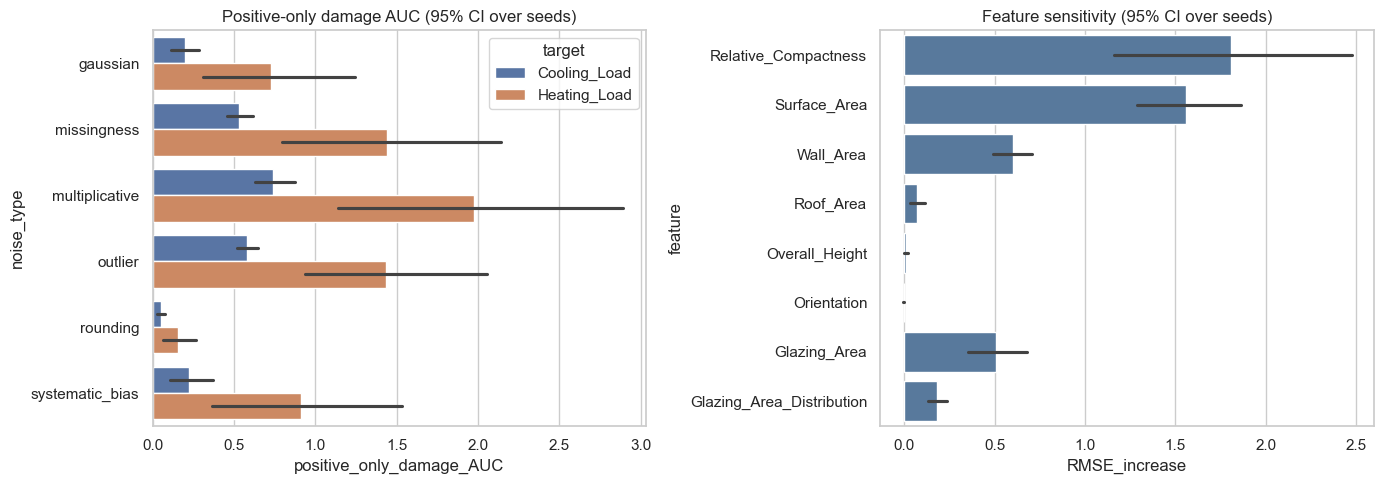

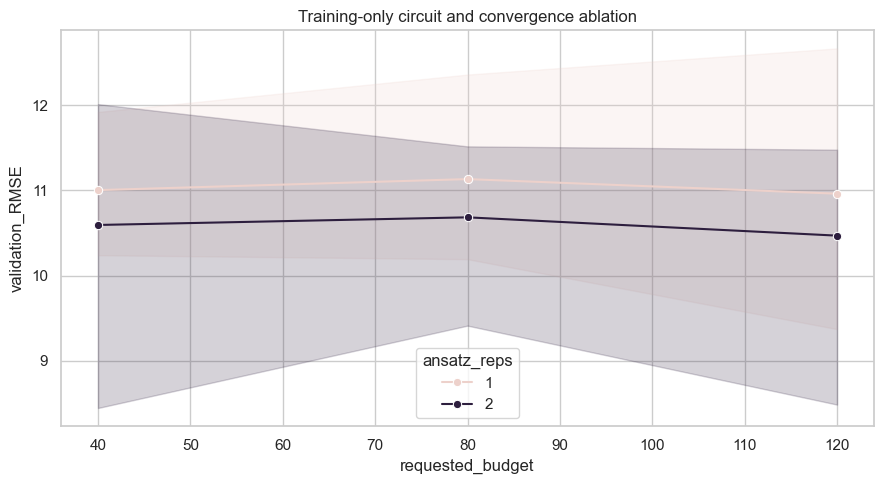

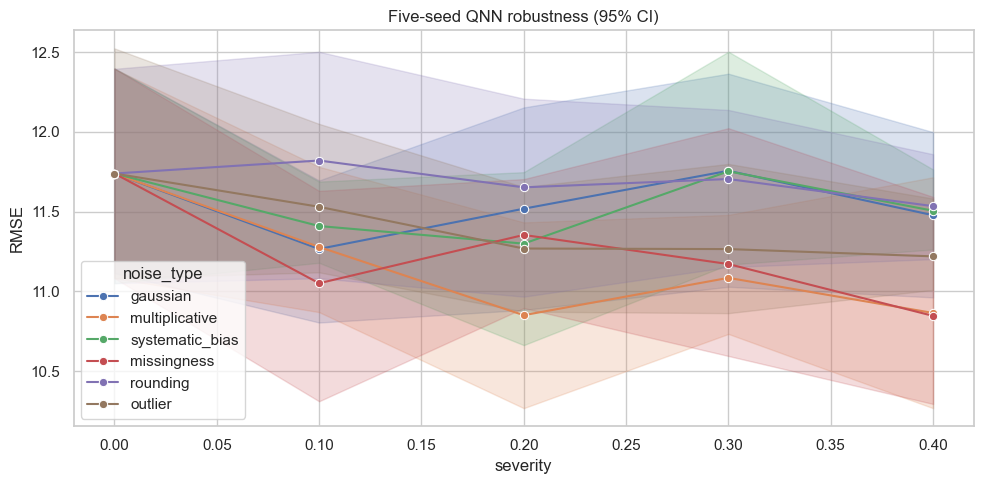

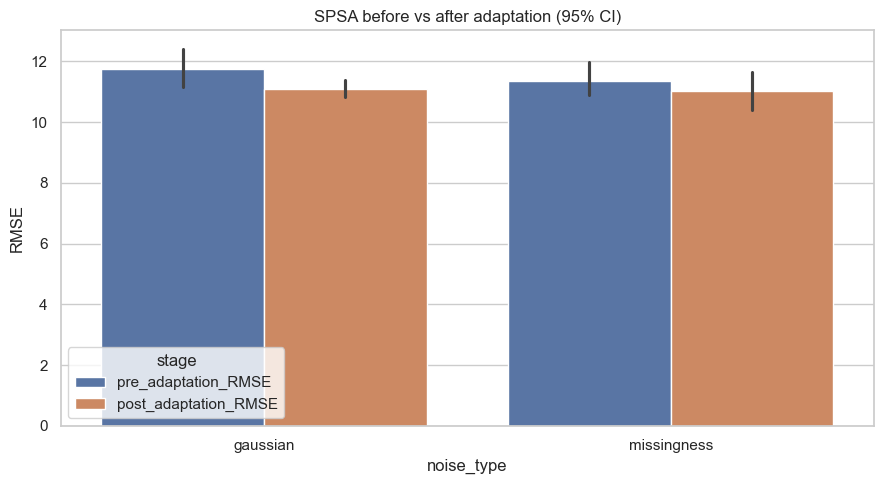

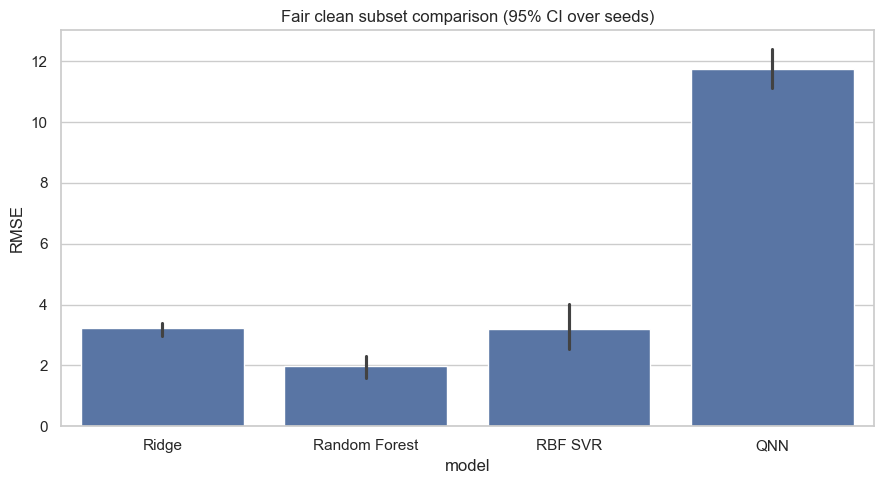

In [15]:
sensitivity_rows = []
for seed, run in classical_runs.items():
    model = run["models"][("Heating_Load", "Random Forest")]
    clean_rmse = regression_metrics(
        run["y_test"].Heating_Load, model.predict(run["X_test"])
    )["RMSE"]
    roles = seed_roles(seed)
    for feature_index, feature in enumerate(FEATURES):
        noise_type = "gaussian" if feature in CONTINUOUS else "missingness"
        noisy = add_noise(
            run["X_test"], noise_type, 0.3,
            roles["test_corruption"] + 7000 + feature_index,
            run["noise_stats"], feature_only=feature
        )
        noisy_rmse = regression_metrics(
            run["y_test"].Heating_Load, model.predict(noisy)
        )["RMSE"]
        sensitivity_rows.append({
            "seed": seed, "feature": feature, "noise_type": noise_type,
            "RMSE_increase": noisy_rmse - clean_rmse
        })

feature_sensitivity = pd.DataFrame(sensitivity_rows)
feature_sensitivity_summary = summarize_across_seeds(
    feature_sensitivity, ["feature", "noise_type"], ["RMSE_increase"]
).sort_values("RMSE_increase_mean", ascending=False)
feature_sensitivity.to_csv(RESULTS_DIR/"tables"/"feature_sensitivity_by_seed.csv", index=False)
feature_sensitivity_summary.to_csv(
    RESULTS_DIR/"tables"/"feature_sensitivity_summary.csv", index=False
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(
    data=damage_auc_by_seed, x="positive_only_damage_AUC", y="noise_type",
    hue="target", errorbar=("ci", 95), ax=axes[0]
)
axes[0].set_title("Positive-only damage AUC (95% CI over seeds)")
sns.barplot(
    data=feature_sensitivity, x="RMSE_increase", y="feature",
    color="#4C78A8", errorbar=("ci", 95), ax=axes[1]
)
axes[1].set_title("Feature sensitivity (95% CI over seeds)")
fig.tight_layout()
fig.savefig(RESULTS_DIR/"plots"/"target_auc_and_feature_sensitivity.png", dpi=180)
plt.show()

if len(ablation_summary):
    plt.figure(figsize=(9, 5))
    sns.lineplot(
        data=circuit_ablation, x="requested_budget", y="validation_RMSE",
        hue="ansatz_reps", marker="o", errorbar=("ci", 95)
    )
    plt.title("Training-only circuit and convergence ablation")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR/"plots"/"circuit_ablation.png", dpi=180)
    plt.show()

if len(quantum_robustness):
    plt.figure(figsize=(10, 5))
    sns.lineplot(
        data=quantum_robustness, x="severity", y="RMSE", hue="noise_type",
        marker="o", errorbar=("ci", 95)
    )
    plt.title("Five-seed QNN robustness (95% CI)")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR/"plots"/"quantum_robustness_five_seeds.png", dpi=180)
    plt.show()

if len(spsa_results):
    plot_spsa = spsa_results.melt(
        id_vars=["seed", "noise_type", "severity"],
        value_vars=["pre_adaptation_RMSE", "post_adaptation_RMSE"],
        var_name="stage", value_name="RMSE"
    )
    plt.figure(figsize=(9, 5))
    sns.barplot(
        data=plot_spsa, x="noise_type", y="RMSE", hue="stage",
        errorbar=("ci", 95)
    )
    plt.title("SPSA before vs after adaptation (95% CI)")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR/"plots"/"spsa_five_seeds.png", dpi=180)
    plt.show()

if len(fair_comparison):
    clean_fair = fair_comparison[
        (fair_comparison.noise_type == "gaussian") & (fair_comparison.severity == 0)
    ]
    plt.figure(figsize=(9, 5))
    sns.barplot(data=clean_fair, x="model", y="RMSE", errorbar=("ci", 95))
    plt.title("Fair clean subset comparison (95% CI over seeds)")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR/"plots"/"fair_subset_five_seeds.png", dpi=180)
    plt.show()


## 16. Findings generated only from executed results

The text below is deliberately conservative: it reports descriptive repeated-seed estimates and avoids converting five runs into strong claims of superiority.


In [16]:
findings = [
    "Result status: FULL five-seed experiment.",
    "Uncertainty: sample SD and two-sided 95% Student-t CI across independent seed-level runs."
]

if len(damage_auc_by_target):
    for target in TARGETS:
        table = damage_auc_by_target[damage_auc_by_target.target == target]
        worst = table.loc[table.positive_only_damage_AUC_mean.idxmax()]
        findings.append(
            f"{target}: largest mean positive-only damage AUC = "
            f"{worst.noise_type} / {worst.model} "
            f"({worst.positive_only_damage_AUC_mean:.3f}, "
            f"95% CI {worst.positive_only_damage_AUC_ci95_low:.3f} to "
            f"{worst.positive_only_damage_AUC_ci95_high:.3f})."
        )

if len(quantum_baseline_summary):
    row = quantum_baseline_summary.iloc[0]
    findings.append(
        f"Clean QNN RMSE across {int(row.n_seeds)} seeds: "
        f"{row.RMSE_mean:.3f} ± {row.RMSE_sd:.3f} SD "
        f"(95% CI {row.RMSE_ci95_low:.3f} to {row.RMSE_ci95_high:.3f})."
    )
else:
    findings.append("Quantum results unavailable; inspect the Qiskit import/smoke-test message.")

if len(spsa_summary):
    for row in spsa_summary.itertuples():
        findings.append(
            f"SPSA under {row.noise_type} at severity {row.severity:.1f}: "
            f"mean absolute RMSE recovery {row.absolute_recovery_mean:.3f} "
            f"(95% CI {row.absolute_recovery_ci95_low:.3f} to "
            f"{row.absolute_recovery_ci95_high:.3f}); "
            f"{int(row.successful_recoveries)}/{int(row.total_runs)} seeds improved."
        )

if len(feature_sensitivity_summary):
    top = feature_sensitivity_summary.iloc[0]
    findings.append(
        f"Largest mean one-feature RMSE increase: {top.feature} "
        f"({top.RMSE_increase_mean:.3f})."
    )

findings.append(
    "Interpretation boundary: this simulated, PCA-compressed, statevector study does not establish quantum advantage."
)
print(*findings, sep="\n")
_ = (RESULTS_DIR/"findings.txt").write_text("\n".join(findings), encoding="utf-8")


Result status: FULL five-seed experiment.
Uncertainty: sample SD and two-sided 95% Student-t CI across independent seed-level runs.
Heating_Load: largest mean positive-only damage AUC = multiplicative / Random Forest (4.541, 95% CI 3.712 to 5.369).
Cooling_Load: largest mean positive-only damage AUC = multiplicative / Random Forest (1.049, 95% CI 0.815 to 1.284).
Clean QNN RMSE across 5 seeds: 11.739 ± 0.869 SD (95% CI 10.660 to 12.818).
SPSA under gaussian at severity 0.3: mean absolute RMSE recovery 0.667 (95% CI -0.171 to 1.505); 4/5 seeds improved.
SPSA under missingness at severity 0.3: mean absolute RMSE recovery 0.338 (95% CI -0.157 to 0.833); 4/5 seeds improved.
Largest mean one-feature RMSE increase: Relative_Compactness (1.807).
Interpretation boundary: this simulated, PCA-compressed, statevector study does not establish quantum advantage.


## 17. Limitations and reproducibility statement

- ENB2012 is a small simulated-building benchmark, not a deployment dataset.
- The six corruptions are controlled stress tests, not learned field-error distributions.
- Five seeds quantify algorithmic and sampling variability only coarsely; confidence intervals will be wide.
- Multiple model/noise/target comparisons are exploratory. No unadjusted p-value is used to declare a winner.
- The QNN uses four PCA components, shallow circuits, and noiseless statevector simulation.
- Circuit selection is training-only, but the small ablation and optimizer budgets do not prove convergence.
- Runtime comparisons are hardware- and software-dependent.

For the paper, report raw seed-level tables, mean ± sample SD, and 95% t-intervals. Describe matched-noise and SPSA analyses as secondary. Avoid “quantum advantage” language.


In [17]:
package_versions = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": __import__("scipy").__version__,
    "scikit_learn": __import__("sklearn").__version__,
    "seaborn": sns.__version__,
    "qiskit": getattr(qiskit, "__version__", None) if QISKIT_AVAILABLE else None,
    "qiskit_machine_learning": getattr(qiskit_machine_learning, "__version__", None) if QISKIT_AVAILABLE else None,
}
reproducibility = {
    "experiment_mode": "FULL_5_SEEDS",
    "experiment_seeds": EXPERIMENT_SEEDS,
    "seed_roles": {str(seed): seed_roles(seed) for seed in EXPERIMENT_SEEDS},
    "replication_unit": "one complete seed-level run",
    "noise_reference": "seed-specific training split (quantum: training subset)",
    "noise_std_ddof": 1,
    "severity_pairing": "common random stream within seed/noise across severities",
    "uncertainty": "sample SD, SE, and two-sided 95% Student-t CI across seeds",
    "auc_protocol": "integrate within seed, then summarize across seeds",
    "selected_ansatz_reps": SELECTED_ANSATZ_REPS,
    "selected_qnn_budget": SELECTED_QNN_BUDGET,
    "spsa_iterations": SPSA_ITERATIONS,
    "result_tables_directory": str((RESULTS_DIR/"tables").resolve()),
    "plots_directory": str((RESULTS_DIR/"plots").resolve()),
    "package_versions": package_versions,
}
print(json.dumps(reproducibility, indent=2, default=str))
_ = (RESULTS_DIR/"reproducibility.json").write_text(
    json.dumps(reproducibility, indent=2, default=str), encoding="utf-8"
)


{
  "experiment_mode": "FULL_5_SEEDS",
  "experiment_seeds": [
    11,
    23,
    42,
    71,
    101
  ],
  "seed_roles": {
    "11": {
      "split": 11,
      "subset": 111,
      "initialization": 211,
      "train_corruption": 311,
      "test_corruption": 411,
      "spsa": 511
    },
    "23": {
      "split": 23,
      "subset": 123,
      "initialization": 223,
      "train_corruption": 323,
      "test_corruption": 423,
      "spsa": 523
    },
    "42": {
      "split": 42,
      "subset": 142,
      "initialization": 242,
      "train_corruption": 342,
      "test_corruption": 442,
      "spsa": 542
    },
    "71": {
      "split": 71,
      "subset": 171,
      "initialization": 271,
      "train_corruption": 371,
      "test_corruption": 471,
      "spsa": 571
    },
    "101": {
      "split": 101,
      "subset": 201,
      "initialization": 301,
      "train_corruption": 401,
      "test_corruption": 501,
      "spsa": 601
    }
  },
  "replication_unit": "one comple